<a href="https://colab.research.google.com/github/leeale2023/BA305_A9-/blob/main/final_chocolate_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Walk-Through Guide: Chocolate Quality Prediction Pipeline

This document walks through the complete end-to-end machine learning project designed to predict chocolate bar ratings using physical attributes (cocoa percentage, ingredients, origins, and manufacturing locations) and unstructured text-based sensory tasting reviews.

---

## Table of Contents
1. [Project Objective](#1-project-objective)
2. [Data Source & Cleaning](#2-data-source--cleaning)
3. [Feature Engineering: Unlocking Unstructured Text](#3-feature-engineering-unlocking-unstructured-text)
4. [Model Development Stages](#4-model-development-stages)
   - *Pre-Tasting Baseline Models*
   - *Sensory-Enhanced Regression Models*
5. [Hyperparameter Optimization](#5-hyperparameter-optimization)
6. [Final Evaluation & Insights](#6-final-evaluation--insights)
7. [Actionable Recommendations: The Ideal Chocolate Bar](#7-actionable-recommendations-the-ideal-chocolate-bar)

---

## 1. Project Objective
The primary objective of this project is to model and predict the quality rating of chocolate bars on a scale of 1.0 to 5.0.

By comparing predictions made **before tasting** (relying only on cocoa content, origin, and recipe) against those made **after tasting** (incorporating sensory descriptors), we quantify exactly how much sensory text boosts predictive accuracy. This yields valuable product-design insights for chocolate makers and suppliers.

---

## 2. Data Source & Cleaning
* **Source**: The project loads a dataset containing **2,530 unique chocolate bar reviews**.
* **Cleaning**:
  * Handled the raw `cocoa_percent` feature (stored as a string such as `'76%'`) by stripping the percentage sign and casting it to a float `cocoa_numeric`.
  * Evaluated missing data: only the `ingredients` column contains minor missingness (~3.4%), which is handled gracefully by pandas or imputed within categorical dummies.
* **Validation Split**: The dataset is split into **70% Training (1,771 samples)** and **30% Testing (759 samples)** to ensure robust, leak-free validation.

---

## 3. Feature Engineering: Unlocking Unstructured Text
The column `most_memorable_characteristics` contains raw comma-separated text descriptors (e.g., `"rich cocoa, fatty, bready"`). To turn this into a predictive numeric feature without introducing target leakage, the project uses a highly disciplined, two-stage vectorization pipeline:

1. **Vectorization & Fit**: A `CountVectorizer` converts the raw training strings into binary token presence columns, filtering out common filler stop words (e.g., `"and"`, `"with"`, `"of"`).
2. **Supervised Sentiment Scorer**: A regularized `RidgeCV` regression model is fit **only on the training split** targets using the token counts. This outputs a stable "impact coefficient" for each vocabulary word.
3. **Test Mapping**: The test set reviews are mapped strictly using these pre-learned coefficients, calculating the mean of known word scores. This avoids target leakage, resulting in a healthy, robust generalization score on out-of-sample data.

---

## 4. Model Development Stages
We split the modeling approach into two distinct eras to show the incremental value of sensory data:

### Phase A: Pre-Tasting Models
These models predict ratings using only the objective recipe and origin criteria (`country_of_bean_origin`, `company_location`, `ingredients`, and `cocoa_numeric`).
* **Algorithms Trained**: K-Nearest Neighbors (KNN), Decision Trees, and Gradient Boosting Regressors.
* **Outcome**: Performance capped out with a **Test RMSE of ~0.403**.

### Phase B: Sensory-Enhanced Models
By joining the engineered `sentiment_total` text feature with the categorical dummied baseline data, we rebuilt the regression space.
* **Outcome**: Performance improved significantly across all models, with Gradient Boosting and Random Forest dropping the **Test RMSE to ~0.303**—a **~25% absolute error reduction**.

---

## 5. Hyperparameter Optimization
To squeeze maximum performance out of our models, the pipeline employs a 5-Fold Cross-Validation grid search on the training split:

* **Decision Trees**: Optimizes `max_depth` and `min_samples_leaf` to prevent overfitting.
* **Random Forest**: Tunes trees count, max depth, pruning factors (`ccp_alpha`), and random feature splits (`max_features`).
* **Gradient Boosting**: Systematically searches grid ranges of `n_estimators`, `learning_rate`, `max_depth`, and `min_samples_split`.
* **Regularized Linears**: Rigorously evaluates `Ridge` and `Lasso` across 50 logarithmically spaced alpha regularizers.

---

## 6. Final Evaluation & Insights

### Performance Comparison (Sorted by Test RMSE)
Our final models are evaluated across Test Root Mean Squared Error (RMSE), Test Mean Absolute Error (MAE), and Exact Match Accuracy (rounding predictions to the nearest 0.25 increment matches):

1. **Gradient Boosting (Tuned)**: **Test RMSE: 0.303** | **Test MAE: 0.239** | **Exact Match: 35.70%** (Winner)
2. **Random Forest (Tuned)**: **Test RMSE: 0.304** | **Test MAE: 0.240** | **Exact Match: 35.31%**
3. **Lasso Regression**: **Test RMSE: 0.306** | **Test MAE: 0.240** | **Exact Match: 35.70%**
4. **Decision Tree**: **Test RMSE: 0.308** | **Test MAE: 0.242** | **Exact Match: 35.44%**
5. **Ridge Regression**: **Test RMSE: 0.312** | **Test MAE: 0.243** | **Exact Match: 33.86%**
6. **KNN (Tuned)**: **Test RMSE: 0.381** | **Test MAE: 0.309** | **Exact Match: 21.48%**
7. **Dummy Baseline**: **Test RMSE: 0.416** | **Test MAE: 0.342** | **Exact Match: 18.05%**

### Key Takeaways
* **Feature Dominance**: Feature importance plots show that the engineered `sentiment_total` text-sentiment metric accounts for over **85%** of the model’s split decisions.
* **Residual Evaluation**: The typical prediction error is less than one rating step (0.25). There is no systematic model bias (mean signed error is near zero at `-0.007`).
* **Temporal Stability**: Segmenting validation data across different historical milestones (pre-2020 reviews vs. 2020–2023 reviews) demonstrates that predictive accuracy remains highly stable across years.

---

## 7. Actionable Recommendations: The Ideal Chocolate Bar
By analyzing the highest positive coefficients from both our sensory (text coefficients) and non-sensory models, we can synthesize the formula for an elite, high-performing chocolate bar:

* **Top 3 Bean Origins**:
  1. Tobago
  2. U.S.A.
  3. Sao Tome & Principe
* **Top 3 Manufacturing Locations**:
  1. Canada
  2. Austria
  3. Australia
* **Optimal Ingredient Recipe**: `3- B,S,C` (Cocoa Beans, Sugar, Cocoa Butter) or `2- B,S` (Cocoa Beans, Sugar). Highly complex formulas with added vanilla or emulsifiers generally score lower.
* **Winning Flavor Characteristics**: Reviews emphasizing complex, sweet, and bright notes such as **raspberry**, **grape**, **blackberry**, **complex**, and **balanced** maximize quality metrics, whereas words like **chemical**, **pastey**, or **medicinal** must be strictly avoided.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import RidgeCV

from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.decomposition import PCA

from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error

In [2]:
url = "https://raw.githubusercontent.com/leeale2023/BA305_A9-/main/chocolate.csv"

choc = pd.read_csv(url)

print("Dataset shape:", choc.shape)
choc.head()

Dataset shape: (2530, 10)


,ref,company_manufacturer,company_location,review_date,country_of_bean_origin,specific_bean_origin_or_bar_name,cocoa_percent,ingredients,most_memorable_characteristics,rating
0,2454,5150,U.S.A.,2019,Tanzania,"Kokoa Kamili, batch 1",76%,"3- B,S,C","rich cocoa, fatty, bready",3.25
1,2458,5150,U.S.A.,2019,Dominican Republic,"Zorzal, batch 1",76%,"3- B,S,C","cocoa, vegetal, savory",3.50
2,2454,5150,U.S.A.,2019,Madagascar,"Bejofo Estate, batch 1",76%,"3- B,S,C","cocoa, blackberry, full body",3.75
3,2542,5150,U.S.A.,2021,Fiji,"Matasawalevu, batch 1",68%,"3- B,S,C","chewy, off, rubbery",3.00
4,2546,5150,U.S.A.,2021,Venezuela,"Sur del Lago, batch 1",72%,"3- B,S,C","fatty, earthy, moss, nutty,chalky",3.00


In [3]:
choc["cocoa_numeric"] = (
    choc["cocoa_percent"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

choc[["cocoa_percent", "cocoa_numeric"]].head()

,cocoa_percent,cocoa_numeric
0,76%,76.0
1,76%,76.0
2,76%,76.0
3,68%,68.0
4,72%,72.0


In [4]:
columns_used = [
    "company_location",
    "country_of_bean_origin",
    "ingredients",
    "cocoa_numeric",
    "most_memorable_characteristics",
    "rating"
]

missing_summary = pd.DataFrame({
    "Missing": choc[columns_used].isna().sum(),
    "Percent Missing": choc[columns_used].isna().mean() * 100
})

display(missing_summary)

,Missing,Percent Missing
company_location,0,0.000000
country_of_bean_origin,0,0.000000
ingredients,87,3.438735
cocoa_numeric,0,0.000000
most_memorable_characteristics,0,0.000000
rating,0,0.000000


In [5]:
choc_train, choc_test = train_test_split(
    choc,
    test_size=0.3,
    random_state=0
)

print("Training observations:", len(choc_train))
print("Testing observations:", len(choc_test))

Training observations: 1771
Testing observations: 759


In [6]:
C_train = choc_train["most_memorable_characteristics"].fillna("")
y_train_text = choc_train["rating"].values

vec = CountVectorizer(
    binary=True,
    stop_words=["and", "notes", "note", "of", "with", "a", "the","is","not","this","very"]
)

W_train = vec.fit_transform(C_train)

ridge = RidgeCV(
    alphas=np.logspace(-2, 3, 30)
)

ridge.fit(W_train, y_train_text)

word_scores = pd.Series(
    ridge.coef_,
    index=vec.get_feature_names_out()
)

print("Number of learned words:", len(word_scores))

display(
    word_scores.sort_values(ascending=False).head(10)
)

Number of learned words: 458


,0
raspberry,0.232238
grape,0.228401
blackberry,0.221483
complex,0.219470
balanced,0.216853
fig,0.215646
distinct,0.212770
cinnamon,0.208634
dark,0.205689
strawberry,0.205329


In [7]:
analyzer = vec.build_analyzer()

# --- AI-assisted (Claude): fallback dictionary for flavor words not seen in training ---
# Unknown words get a score borrowed from the training data: a misspelling reuses the learned score
# of the correct word, and a new flavor word gets the average learned score of its flavor category.
# A learned score is never overridden.

def category_mean(words):
    known = [w for w in words if w in word_scores.index]
    return word_scores[known].mean()

# Category anchors: averages of learned word scores (training data only)
FRUIT     = category_mean(["raspberry", "blackberry", "cherry", "plum", "strawberry", "berry", "fruit", "citrus"])
QUALITY   = category_mean(["complex", "balanced", "creamy", "distinct", "rich", "smooth", "bright"])
DEFECT    = category_mean(["chemical", "medicinal", "off", "musty", "fuel", "dirt", "pungent", "rubbery", "burnt", "sour"])
MEDICINAL = category_mean(["medicinal", "chemical", "fuel", "rubber", "metallic", "cough"])
STALE     = category_mean(["cardboard", "flat", "bland", "dull", "muted"])
MOLD      = category_mean(["musty", "moldy", "damp"])
FERM      = category_mean(["vinegar", "raw", "green", "astringent"])
SWEET     = category_mean(["cloying", "candy"])
FLORAL    = word_scores["floral"]

# 1) Misspellings / variants -> reuse the learned score of the correct word
SPELLING = {
    "bitterness": "bitter", "overyly": "overly", "carame": "caramel", "cocounut": "coconut", "cooa": "cocoa",
    "raisns": "raisins", "smomkey": "smokey", "smoky": "smokey", "vanila": "vanilla", "sugary": "sugar",
    "blueberries": "blueberry", "peanutbutter": "peanut", "blackpepper": "pepper", "cheesey": "cheesy",
    "winey": "wine", "chocolaty": "chocolate", "earthen": "earthy", "herbaceous": "herbal",
    "domintates": "dominates", "dominated": "dominates", "sligt": "slight", "sligthly": "slightly",
    "accesible": "accessible", "menthol": "mint", "trop": "tropical", "clove": "cinnamon",
}

# 2) New words -> average learned score of their flavor category
CATEGORY_WORDS = {
    DEFECT:    "ashy burlap synthetic alkalyzed soy issues uncontrolled clingy malitol",
    MEDICINAL: "phenolic antiseptic iodine bandaid hospital camphor aspirin pharmaceutical mothball "
               "chlorine bleach disinfectant ammonia petroleum petrol petro gasoline kerosene diesel "
               "tar solvent acetone varnish paint turpentine sulfur sulphur acrid tinny cigarette",
    QUALITY:   "clean nice rounded flavorful perfectly alluring delicious excellent outstanding superb "
               "exquisite wonderful lovely delightful elegant harmonious layered vibrant lively juicy "
               "luscious polished integrated velvety luxurious",
    FRUIT:     "peach gooseberry passionfruit lychee mango guava kiwi currant blackcurrant mulberry "
               "elderberry pomegranate apricot nectarine yuzu",
    FLORAL:    "jasmine rose lavender blossom violet hibiscus honeysuckle flowery flowers",
    STALE:     "rancid stale lifeless weak thin hollow greasy",
    MOLD:      "mouldy mildew dank basement",
    FERM:      "vinegary overfermented underfermented",
    SWEET:     "saccharine oversweet",
}
CATEGORY = {}
for score, words in CATEGORY_WORDS.items():
    for w in words.split():
        if w not in word_scores.index:          # never override a learned score
            CATEGORY.setdefault(w, score)

def word_score(word):
    if word in word_scores.index:
        return word_scores[word]
    if word in SPELLING and SPELLING[word] in word_scores.index:
        return word_scores[SPELLING[word]]
    return CATEGORY.get(word)                   # None if still unknown -> ignored

def score_phrase(phrase):
    phrase = str(phrase).strip().lower()
    if phrase in word_scores.index:
        return word_scores[phrase]
    scores = [s for s in (word_score(w) for w in analyzer(phrase)) if s is not None]
    return np.mean(scores) if scores else 0.0

print(f"Fallback dictionary: {len(SPELLING)} spelling fixes, {len(CATEGORY)} category words")
print({name: round(v, 3) for name, v in [("FRUIT", FRUIT), ("QUALITY", QUALITY), ("DEFECT", DEFECT),
       ("MEDICINAL", MEDICINAL), ("STALE", STALE), ("MOLD", MOLD), ("FERM", FERM), ("SWEET", SWEET), ("FLORAL", FLORAL)]})

def calculate_sentiment_total(series):
    scores = []

    for item in series:
        total = 0.0

        for characteristic in str(item).split(","):
            characteristic = characteristic.strip().lower()

            if characteristic:
                total += score_phrase(characteristic)

        scores.append(total)

    return np.array(scores)

Fallback dictionary: 26 spelling fixes, 104 category words
{'FRUIT': np.float64(0.151), 'QUALITY': np.float64(0.174), 'DEFECT': np.float64(-0.291), 'MEDICINAL': np.float64(-0.286), 'STALE': np.float64(-0.155), 'MOLD': np.float64(-0.148), 'FERM': np.float64(-0.148), 'SWEET': np.float64(-0.125), 'FLORAL': np.float64(0.088)}


In [8]:
sentiment_train = calculate_sentiment_total(
    choc_train["most_memorable_characteristics"]
)

sentiment_test = calculate_sentiment_total(
    choc_test["most_memorable_characteristics"]
)

print("First five training sentiment scores:")
print(sentiment_train[:5])

First five training sentiment scores:
[ 0.0502111  -0.53599159  0.02991055 -0.57357173  0.43318006]


In [9]:
origin_map = {
    "Sao Tome": "Sao Tome & Principe",
    "Principe": "Sao Tome & Principe",
    "Trinidad": "Trinidad & Tobago",
    "Tobago": "Trinidad & Tobago",
    "Sumatra": "Indonesia",
    "Sulawesi": "Indonesia",
}
location_map = {
    "Amsterdam": "Netherlands",
    "Scotland": "U.K.",
    "Wales": "U.K.",
    "Sao Tome": "Sao Tome & Principe",
}
choc["origin_clean"] = choc["country_of_bean_origin"].replace(origin_map)
choc["location_clean"] = choc["company_location"].replace(location_map)
choc["ingredients_clean"] = choc["ingredients"].fillna("Missing")

MIN_BARS = 10

def group_rare(column):
    train_counts = choc.loc[choc_train.index, column].value_counts()
    common = train_counts[train_counts >= MIN_BARS].index
    return choc[column].where(choc[column].isin(common), "Other")

choc["origin_grouped"] = group_rare("origin_clean")
choc["location_grouped"] = group_rare("location_clean")
choc["ingredients_grouped"] = group_rare("ingredients_clean")

print("Bean origins:", choc["country_of_bean_origin"].nunique(), "->", choc["origin_grouped"].nunique())
print("Company locations:", choc["company_location"].nunique(), "->", choc["location_grouped"].nunique())
print("Ingredients:", choc["ingredients"].nunique(dropna=False), "->", choc["ingredients_grouped"].nunique())

origin_dummies = pd.get_dummies(
    choc["origin_grouped"],
    prefix="origin"
)

location_dummies = pd.get_dummies(
    choc["location_grouped"],
    prefix="location"
)

ingredients_dummies = pd.get_dummies(
    choc["ingredients_grouped"],
    prefix="ingredients"
)

X_all = pd.concat([
    origin_dummies,
    location_dummies,
    ingredients_dummies,
    choc[["cocoa_numeric"]]
], axis=1)

print("Number of predictors before sentiment:", X_all.shape[1])

Bean origins: 62 -> 31
Company locations: 67 -> 23
Ingredients: 22 -> 9
Number of predictors before sentiment: 64


In [10]:
X_train = X_all.loc[choc_train.index].copy()
X_test = X_all.loc[choc_test.index].copy()

X_train["sentiment_total"] = sentiment_train
X_test["sentiment_total"] = sentiment_test

y_train = choc_train["rating"].values
y_test = choc_test["rating"].values

print("X train shape:", X_train.shape)
print("X test shape:", X_test.shape)

X train shape: (1771, 65)
X test shape: (759, 65)


In [11]:
pre_features = [
    col for col in X_train.columns
    if col != "sentiment_total"
]

X_train_pre = X_train[pre_features].copy()
X_test_pre = X_test[pre_features].copy()

print("Pre-tasting train shape:", X_train_pre.shape)
print("Pre-tasting test shape:", X_test_pre.shape)

Pre-tasting train shape: (1771, 64)
Pre-tasting test shape: (759, 64)


In [12]:
# Pre-tasting KNN

scaler_pre = StandardScaler()

X_train_pre_scaled = scaler_pre.fit_transform(X_train_pre)
X_test_pre_scaled = scaler_pre.transform(X_test_pre)

knn_pre = KNeighborsRegressor(
    n_neighbors=50,
    weights="uniform"
)

knn_pre.fit(
    X_train_pre_scaled,
    y_train
)

y_test_pred_knn_pre = knn_pre.predict(
    X_test_pre_scaled
)

knn_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_knn_pre)
)

knn_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_knn_pre
)

print(f"Pre-tasting KNN Test RMSE: {knn_pre_rmse:.3f}")
print(f"Pre-tasting KNN Test MAE:  {knn_pre_mae:.3f}")

Pre-tasting KNN Test RMSE: 0.411
Pre-tasting KNN Test MAE:  0.335


In [13]:
# Pre-tasting Decision Tree

dt_pre = DecisionTreeRegressor(
    max_depth=4,
    min_samples_leaf=5,
    random_state=0
)

dt_pre.fit(
    X_train_pre,
    y_train
)

y_test_pred_dt_pre = dt_pre.predict(
    X_test_pre
)

dt_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dt_pre)
)

dt_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_dt_pre
)

print(f"Pre-tasting Decision Tree Test RMSE: {dt_pre_rmse:.3f}")
print(f"Pre-tasting Decision Tree Test MAE:  {dt_pre_mae:.3f}")# Pre-tasting Gradient Boosting

gb_pre = GradientBoostingRegressor(
    random_state=0
)

gb_pre.fit(
    X_train_pre,
    y_train
)

y_test_pred_gb_pre = gb_pre.predict(
    X_test_pre
)

gb_pre_rmse = np.sqrt(
    MSE(y_test, y_test_pred_gb_pre)
)

gb_pre_mae = mean_absolute_error(
    y_test,
    y_test_pred_gb_pre
)

print(f"Pre-tasting Gradient Boosting Test RMSE: {gb_pre_rmse:.3f}")
print(f"Pre-tasting Gradient Boosting Test MAE:  {gb_pre_mae:.3f}")

Pre-tasting Decision Tree Test RMSE: 0.408
Pre-tasting Decision Tree Test MAE:  0.331
Pre-tasting Gradient Boosting Test RMSE: 0.403
Pre-tasting Gradient Boosting Test MAE:  0.327


In [14]:
# Tune pre-tasting KNN

neighbors_list = [1, 5, 10, 50, 100]
weights_list = ["uniform", "distance"]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_pre_results = []

for weight in weights_list:
    for k in neighbors_list:

        model = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight
        )

        cv_scores = cross_val_score(
            model,
            X_train_pre_scaled,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        knn_pre_results.append([
            k,
            weight,
            cv_rmse
        ])

knn_pre_results = pd.DataFrame(
    knn_pre_results,
    columns=[
        "Neighbors",
        "Weight",
        "CV RMSE"
    ]
)

knn_pre_results = knn_pre_results.sort_values(
    "CV RMSE"
)

display(knn_pre_results)

,Neighbors,Weight,CV RMSE
3,50,uniform,0.447861
4,100,uniform,0.449830
2,10,uniform,0.454568
1,5,uniform,0.464133
9,100,distance,0.469701
8,50,distance,0.469985
7,10,distance,0.476619
6,5,distance,0.482667
5,1,distance,0.562114
0,1,uniform,0.562114


In [15]:
# Tune pre-tasting Decision Tree

depth_list = [2, 3, 4, 5, 6, 8, 10, 12]
leaf_list = [1, 2, 5, 10, 20, 30]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tree_pre_results = []

for depth in depth_list:
    for leaf in leaf_list:

        model = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=0
        )

        cv_scores = cross_val_score(
            model,
            X_train_pre,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        tree_pre_results.append([
            depth,
            leaf,
            cv_rmse
        ])

tree_pre_results = pd.DataFrame(
    tree_pre_results,
    columns=[
        "Max Depth",
        "Min Samples Leaf",
        "CV RMSE"
    ]
)

tree_pre_results = tree_pre_results.sort_values(
    "CV RMSE"
)

display(tree_pre_results.head(15))

,Max Depth,Min Samples Leaf,CV RMSE
20,5,5,0.431348
14,4,5,0.431784
12,4,1,0.434789
26,6,5,0.434951
15,4,10,0.434984
27,6,10,0.435001
21,5,10,0.435050
8,3,5,0.435953
13,4,2,0.436242
19,5,2,0.436428


In [16]:
# Final pre-tasting Decision Tree using tuned settings

best_pre_depth = int(tree_pre_results.iloc[0]["Max Depth"])
best_pre_leaf = int(tree_pre_results.iloc[0]["Min Samples Leaf"])
print("Best pre-tasting tree settings: max_depth =", best_pre_depth, "| min_samples_leaf =", best_pre_leaf)

dt_pre = DecisionTreeRegressor(
    max_depth=best_pre_depth,
    min_samples_leaf=best_pre_leaf,
    random_state=0
)
dt_pre.fit(X_train_pre, y_train)
y_test_pred_dt_pre = dt_pre.predict(X_test_pre)

dt_pre_rmse = np.sqrt(MSE(y_test, y_test_pred_dt_pre))
dt_pre_mae = mean_absolute_error(y_test, y_test_pred_dt_pre)

print(f"Pre-tasting Decision Tree Test RMSE: {dt_pre_rmse:.3f}")
print(f"Pre-tasting Decision Tree Test MAE:  {dt_pre_mae:.3f}")

Best pre-tasting tree settings: max_depth = 5 | min_samples_leaf = 5
Pre-tasting Decision Tree Test RMSE: 0.408
Pre-tasting Decision Tree Test MAE:  0.333


In [17]:
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

y_test_pred_dummy = dummy.predict(X_test)

dummy_rmse = np.sqrt(MSE(y_test, y_test_pred_dummy))
dummy_mae = mean_absolute_error(y_test,y_test_pred_dummy)

y_train_pred_dummy = dummy.predict(X_train)
dummy_train_rmse = np.sqrt(MSE(y_train, y_train_pred_dummy))

print(f"Baseline Train RMSE: {dummy_train_rmse:.3f}")
print(f"Baseline Test RMSE: {dummy_rmse:.3f}")
print(f"Baseline Test MAE:  {dummy_mae:.3f}")

Baseline Train RMSE: 0.457
Baseline Test RMSE: 0.416
Baseline Test MAE:  0.342


In [18]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [19]:
neighbors_list = [1, 5, 10, 50, 100]
weights_list = ["uniform", "distance"]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_results = []

for weight in weights_list:

    for k in neighbors_list:

        model = KNeighborsRegressor(
            n_neighbors=k,
            weights=weight
        )

        cv_scores = cross_val_score(
            model,
            X_train_scaled,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(-cv_scores.mean())

        knn_results.append([
            k,
            weight,
            cv_rmse
        ])

knn_results = pd.DataFrame(
    knn_results,
    columns=[
        "Neighbors",
        "Weight",
        "CV RMSE"
    ]
)

knn_results = knn_results.sort_values(
    "CV RMSE"
)

display(knn_results)

,Neighbors,Weight,CV RMSE
8,50,distance,0.399952
7,10,distance,0.400738
9,100,distance,0.401883
6,5,distance,0.405653
1,5,uniform,0.408936
2,10,uniform,0.409981
4,100,uniform,0.410535
3,50,uniform,0.411502
5,1,distance,0.482214
0,1,uniform,0.482214


In [20]:
best_k = int(knn_results.iloc[0]["Neighbors"])
best_weight = knn_results.iloc[0]["Weight"]

print("Selected number of neighbors:", best_k)
print("Selected weighting:", best_weight)

Selected number of neighbors: 50
Selected weighting: distance


In [21]:
best_knn = KNeighborsRegressor(
    n_neighbors=best_k,
    weights=best_weight
)

best_knn.fit(
    X_train_scaled,
    y_train
)

y_train_pred_knn = best_knn.predict(
    X_train_scaled
)

y_test_pred_knn = best_knn.predict(
    X_test_scaled
)

knn_train_rmse = np.sqrt(
    MSE(y_train, y_train_pred_knn)
)

knn_rmse = np.sqrt(
    MSE(y_test, y_test_pred_knn)
)

knn_mae = mean_absolute_error(
    y_test,
    y_test_pred_knn
)

print(f"KNN Train RMSE: {knn_train_rmse:.3f}")
print(f"KNN Test RMSE:  {knn_rmse:.3f}")
print(f"KNN Test MAE:   {knn_mae:.3f}")

KNN Train RMSE: 0.000
KNN Test RMSE:  0.372
KNN Test MAE:   0.300


In [22]:
depth_list = [2, 3, 4, 5, 6, 8, 10, 12]

leaf_list = [
    1, 2, 5, 10, 20, 30
]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tree_results = []

for depth in depth_list:

    for leaf in leaf_list:

        model = DecisionTreeRegressor(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=0
        )

        cv_scores = cross_val_score(
            model,
            X_train,
            y_train,
            cv=kfold,
            scoring="neg_mean_squared_error"
        )

        cv_rmse = np.sqrt(
            -cv_scores.mean()
        )

        tree_results.append([
            depth,
            leaf,
            cv_rmse
        ])

tree_results = pd.DataFrame(
    tree_results,
    columns=[
        "Max Depth",
        "Min Samples Leaf",
        "CV RMSE"
    ]
)

tree_results = tree_results.sort_values(
    "CV RMSE"
)

display(tree_results.head(15))

,Max Depth,Min Samples Leaf,CV RMSE
9,3,10,0.310642
13,4,2,0.312350
6,3,1,0.312389
7,3,2,0.312389
8,3,5,0.312389
17,4,30,0.312430
15,4,10,0.312767
11,3,30,0.313477
16,4,20,0.313799
12,4,1,0.314009


In [23]:
best_depth = int(
    tree_results.iloc[0]["Max Depth"]
)

best_leaf = int(
    tree_results.iloc[0]["Min Samples Leaf"]
)

print("Best max depth:", best_depth)
print("Best min samples leaf:", best_leaf)
print(
    "Best CV RMSE:",
    round(tree_results.iloc[0]["CV RMSE"], 3)
)

Best max depth: 3
Best min samples leaf: 10
Best CV RMSE: 0.311


In [24]:
best_dt = DecisionTreeRegressor(
    max_depth=best_depth,
    min_samples_leaf=best_leaf,
    random_state=0
)

best_dt.fit(
    X_train,
    y_train
)

y_train_pred_dt = best_dt.predict(
    X_train
)

y_test_pred_dt = best_dt.predict(
    X_test
)

dt_train_rmse = np.sqrt(
    MSE(y_train, y_train_pred_dt)
)

dt_rmse = np.sqrt(
    MSE(y_test, y_test_pred_dt)
)

dt_mae = mean_absolute_error(
    y_test,
    y_test_pred_dt
)

print(f"Decision Tree Train RMSE: {dt_train_rmse:.3f}")
print(f"Decision Tree Test RMSE:  {dt_rmse:.3f}")
print(f"Decision Tree Test MAE:   {dt_mae:.3f}")

Decision Tree Train RMSE: 0.301
Decision Tree Test RMSE:  0.313
Decision Tree Test MAE:   0.248


In [25]:
best_boost = GradientBoostingRegressor(random_state=0)

best_boost.fit(X_train, y_train)

y_train_pred_boost = best_boost.predict(X_train)
y_test_pred_boost = best_boost.predict(X_test)

boost_train_rmse = np.sqrt(MSE(y_train, y_train_pred_boost))
boost_rmse = np.sqrt(MSE(y_test, y_test_pred_boost))
boost_mae = mean_absolute_error(y_test, y_test_pred_boost)

print(f"Gradient Boosting Train RMSE: {boost_train_rmse:.3f}")
print(f"Gradient Boosting Test RMSE: {boost_rmse:.3f}")
print(f"Gradient Boosting Test MAE: {boost_mae:.3f}")

Gradient Boosting Train RMSE: 0.258
Gradient Boosting Test RMSE: 0.304
Gradient Boosting Test MAE: 0.237


In [26]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_val_score

# Define the hyperparameter search grid for Gradient Boosting
n_estimators_list = [25,50, 100, 200,300]
learning_rate_list = [0.01, 0.05, 0.1,0.2]
max_depth_list = [1,2, 3, 4, 5]
min_samples_split_list = [2, 10]

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
gb_cv_results = []

print("Starting Gradient Boosting Hyperparameter Tuning via Cross-Validation...")

for n_est in n_estimators_list:
    for lr in learning_rate_list:
        for depth in max_depth_list:
            for min_split in min_samples_split_list:
                model = GradientBoostingRegressor(
                    n_estimators=n_est,
                    learning_rate=lr,
                    max_depth=depth,
                    min_samples_split=min_split,
                    random_state=0
                )

                cv_scores = cross_val_score(
                    model,
                    X_train,
                    y_train,
                    cv=kfold,
                    scoring='neg_mean_squared_error',
                    n_jobs=-1
                )

                cv_rmse = np.sqrt(-cv_scores.mean())
                gb_cv_results.append([n_est, lr, depth, min_split, cv_rmse])

gb_cv_results_df = pd.DataFrame(
    gb_cv_results,
    columns=['n_estimators', 'learning_rate', 'max_depth', 'min_samples_split', 'CV RMSE']
).sort_values('CV RMSE')

display(gb_cv_results_df.head(10))

Starting Gradient Boosting Hyperparameter Tuning via Cross-Validation...


,n_estimators,learning_rate,max_depth,min_samples_split,CV RMSE
143,200,0.10,2,10,0.299198
103,100,0.10,2,10,0.299362
102,100,0.10,2,2,0.299420
132,200,0.05,2,2,0.299501
142,200,0.10,2,2,0.299544
172,300,0.05,2,2,0.299555
73,50,0.20,2,10,0.299753
173,300,0.05,2,10,0.299816
133,200,0.05,2,10,0.300081
63,50,0.10,2,10,0.300254


In [27]:
from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error

# Extract the best hyperparameters found
best_gb_row = gb_cv_results_df.iloc[0]
best_n_est = int(best_gb_row['n_estimators'])
best_lr = best_gb_row['learning_rate']
best_max_depth = int(best_gb_row['max_depth'])
best_min_split = int(best_gb_row['min_samples_split'])

print(f"Best Parameters Found:")
print(f"  - n_estimators: {best_n_est}")
print(f"  - learning_rate: {best_lr}")
print(f"  - max_depth: {best_max_depth}")
print(f"  - min_samples_split: {best_min_split}")
print(f"  - Best CV RMSE: {best_gb_row['CV RMSE']:.4f}\n")

# Retrain the optimal Gradient Boosting Regressor
best_boost = GradientBoostingRegressor(
    n_estimators=best_n_est,
    learning_rate=best_lr,
    max_depth=best_max_depth,
    min_samples_split=best_min_split,
    random_state=0
)

best_boost.fit(X_train, y_train)

# Predict and evaluate performance metrics
y_train_pred_boost = best_boost.predict(X_train)
y_test_pred_boost = best_boost.predict(X_test)

boost_train_rmse = np.sqrt(MSE(y_train, y_train_pred_boost))
boost_rmse = np.sqrt(MSE(y_test, y_test_pred_boost))
boost_mae = mean_absolute_error(y_test, y_test_pred_boost)

print("--- Retrained Gradient Boosting Performance ---")
print(f"Train RMSE: {boost_train_rmse:.3f}")
print(f"Test RMSE:  {boost_rmse:.3f}")
print(f"Test MAE:   {boost_mae:.3f}")

Best Parameters Found:
  - n_estimators: 200
  - learning_rate: 0.1
  - max_depth: 2
  - min_samples_split: 10
  - Best CV RMSE: 0.2992

--- Retrained Gradient Boosting Performance ---
Train RMSE: 0.267
Test RMSE:  0.303
Test MAE:   0.236


In [28]:
from sklearn.ensemble import RandomForestRegressor

estimators_list = [50, 100, 200]
max_depth_list = [4, 6, 8, 10]
ccp_alpha_list = [0.0, 0.001, 0.01]
max_features_list = ["sqrt", "log2", 0.5, 1.0]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_results = []

for n_est in estimators_list:
    for depth in max_depth_list:
        for alpha in ccp_alpha_list:
            for max_feat in max_features_list:
                model = RandomForestRegressor(
                    n_estimators=n_est,
                    max_depth=depth,
                    ccp_alpha=alpha,
                    max_features=max_feat,
                    random_state=0,
                    n_jobs=-1
                )

                cv_scores = cross_val_score(
                    model,
                    X_train,
                    y_train,
                    cv=kfold,
                    scoring="neg_mean_squared_error"
                )

                cv_rmse = np.sqrt(
                    -cv_scores.mean()
                )

                rf_results.append([
                    n_est,
                    depth,
                    alpha,
                    str(max_feat),
                    cv_rmse
                ])

rf_results = pd.DataFrame(
    rf_results,
    columns=[
        "n_estimators",
        "Max Depth",
        "ccp_alpha",
        "max_features",
        "CV RMSE"
    ]
)

rf_results = rf_results.sort_values(
    "CV RMSE"
)

display(rf_results.head(15))

,n_estimators,Max Depth,ccp_alpha,max_features,CV RMSE
74,100,8,0.000,0.5,0.299810
122,200,8,0.000,0.5,0.299985
26,50,8,0.000,0.5,0.300358
134,200,10,0.000,0.5,0.300887
86,100,10,0.000,0.5,0.301171
78,100,8,0.001,0.5,0.301623
110,200,6,0.000,0.5,0.301633
90,100,10,0.001,0.5,0.301641
14,50,6,0.000,0.5,0.301698
62,100,6,0.000,0.5,0.301720


In [29]:
best_rf_row = rf_results.iloc[0]
best_max_feat = best_rf_row["max_features"]
best_max_feat = best_max_feat if best_max_feat in ("sqrt", "log2") else float(best_max_feat)

best_rf = RandomForestRegressor(
    n_estimators=int(best_rf_row["n_estimators"]),
    max_depth=int(best_rf_row["Max Depth"]),
    ccp_alpha=float(best_rf_row["ccp_alpha"]),
    max_features=best_max_feat,
    random_state=0,
    n_jobs=-1
)
best_rf.fit(X_train, y_train)

y_train_pred_rf = best_rf.predict(X_train)
y_test_pred_rf = best_rf.predict(X_test)

rf_train_rmse = np.sqrt(MSE(y_train, y_train_pred_rf))
rf_rmse = np.sqrt(MSE(y_test, y_test_pred_rf))
rf_mae = mean_absolute_error(y_test, y_test_pred_rf)

print(f"Random Forest Train RMSE: {rf_train_rmse:.3f}")
print(f"Random Forest Test RMSE:  {rf_rmse:.3f}")
print(f"Random Forest Test MAE:   {rf_mae:.3f}")

Random Forest Train RMSE: 0.246
Random Forest Test RMSE:  0.303
Random Forest Test MAE:   0.237


In [30]:
hidden_layer_list = [(50,), (100,), (50, 50)]
activation_list = ["relu", "tanh"]
alpha_list = [0.0001, 0.001, 0.01]

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

mlp_results = []

for hidden in hidden_layer_list:
    for activation in activation_list:
        for alpha in alpha_list:
            model = MLPRegressor(
                hidden_layer_sizes=hidden,
                activation=activation,
                alpha=alpha,
                random_state=0,
                max_iter=1500,  # Increased to prevent convergence issues
                early_stopping=True,  # Stops training early if validation score does not improve
                validation_fraction=0.1
            )

            cv_scores = cross_val_score(
                model,
                X_train_scaled,  # MLPs are sensitive to feature scaling
                y_train,
                cv=kfold,
                scoring="neg_mean_squared_error"
            )

            cv_rmse = np.sqrt(
                -cv_scores.mean()
            )

            mlp_results.append([
                str(hidden),
                activation,
                alpha,
                cv_rmse
            ])

mlp_results = pd.DataFrame(
    mlp_results,
    columns=[
        "hidden_layer_sizes",
        "activation",
        "alpha",
        "CV RMSE"
    ]
)

mlp_results = mlp_results.sort_values(
    "CV RMSE"
)

display(mlp_results.head(15))

,hidden_layer_sizes,activation,alpha,CV RMSE
8,"(100,)",relu,0.0100,0.388184
7,"(100,)",relu,0.0010,0.389259
6,"(100,)",relu,0.0001,0.389286
14,"(50, 50)",relu,0.0100,0.390240
13,"(50, 50)",relu,0.0010,0.390648
12,"(50, 50)",relu,0.0001,0.390682
11,"(100,)",tanh,0.0100,0.392132
10,"(100,)",tanh,0.0010,0.392624
9,"(100,)",tanh,0.0001,0.392673
17,"(50, 50)",tanh,0.0100,0.392758


In [31]:
from sklearn.neural_network import MLPRegressor
import ast

# Extract the best parameters from the cv results
best_hidden_str = mlp_results["hidden_layer_sizes"].iloc[0]
best_hidden = ast.literal_eval(best_hidden_str)
best_activation = mlp_results["activation"].iloc[0]
best_alpha = mlp_results["alpha"].iloc[0]

# Initialize the best MLPRegressor model
best_mlp = MLPRegressor(
    hidden_layer_sizes=best_hidden,
    activation=best_activation,
    alpha=best_alpha,
    random_state=0,
    max_iter=1500,
    early_stopping=True,
    validation_fraction=0.1
)

# Fit on the scaled training set
best_mlp.fit(X_train_scaled, y_train)

# Predict
y_train_pred_mlp = best_mlp.predict(X_train_scaled)
y_test_pred_mlp = best_mlp.predict(X_test_scaled)

# Evaluate
mlp_train_rmse = np.sqrt(MSE(y_train, y_train_pred_mlp))
mlp_rmse = np.sqrt(MSE(y_test, y_test_pred_mlp))
mlp_mae = mean_absolute_error(y_test, y_test_pred_mlp)

print(f"MLP Train RMSE: {mlp_train_rmse:.3f}")
print(f"MLP Test RMSE:  {mlp_rmse:.3f}")
print(f"MLP Test MAE:   {mlp_mae:.3f}")

MLP Train RMSE: 0.243
MLP Test RMSE:  0.375
MLP Test MAE:   0.292


### Tuning and Evaluating Regularized Linear Models (Ridge & Lasso)

In [32]:
from sklearn.linear_model import Ridge, Lasso

alphas = np.logspace(-4, 4, 50)
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_results = []
lasso_results = []

for a in alphas:
    # Ridge tuning
    ridge_model = Ridge(alpha=a, random_state=0)
    ridge_scores = cross_val_score(ridge_model, X_train_scaled, y_train, cv=kfold, scoring='neg_mean_squared_error')
    ridge_results.append([a, np.sqrt(-ridge_scores.mean())])

    # Lasso tuning
    lasso_model = Lasso(alpha=a, random_state=0, max_iter=5000)
    lasso_scores = cross_val_score(lasso_model, X_train_scaled, y_train, cv=kfold, scoring='neg_mean_squared_error')
    lasso_results.append([a, np.sqrt(-lasso_scores.mean())])

ridge_df = pd.DataFrame(ridge_results, columns=['alpha', 'CV RMSE']).sort_values('CV RMSE')
lasso_df = pd.DataFrame(lasso_results, columns=['alpha', 'CV RMSE']).sort_values('CV RMSE')

best_ridge_alpha = ridge_df.iloc[0]['alpha']
best_lasso_alpha = lasso_df.iloc[0]['alpha']

print(f"Best Ridge Alpha: {best_ridge_alpha:.4f} | Best CV RMSE: {ridge_df.iloc[0]['CV RMSE']:.4f}")
print(f"Best Lasso Alpha: {best_lasso_alpha:.4f} | Best CV RMSE: {lasso_df.iloc[0]['CV RMSE']:.4f}")

Best Ridge Alpha: 51.7947 | Best CV RMSE: 0.3071
Best Lasso Alpha: 0.0091 | Best CV RMSE: 0.3036


In [33]:
# Train & Evaluate Best Ridge Model
best_ridge = Ridge(alpha=best_ridge_alpha, random_state=0)
best_ridge.fit(X_train_scaled, y_train)

ridge_train_rmse = np.sqrt(MSE(y_train, best_ridge.predict(X_train_scaled)))
ridge_rmse = np.sqrt(MSE(y_test, best_ridge.predict(X_test_scaled)))
ridge_mae = mean_absolute_error(y_test, best_ridge.predict(X_test_scaled))

# Train & Evaluate Best Lasso Model
best_lasso = Lasso(alpha=best_lasso_alpha, random_state=0, max_iter=5000)
best_lasso.fit(X_train_scaled, y_train)

lasso_train_rmse = np.sqrt(MSE(y_train, best_lasso.predict(X_train_scaled)))
lasso_rmse = np.sqrt(MSE(y_test, best_lasso.predict(X_test_scaled)))
lasso_mae = mean_absolute_error(y_test, best_lasso.predict(X_test_scaled))

print("--- Ridge Regression Performance ---")
print(f"Train RMSE: {ridge_train_rmse:.3f}")
print(f"Test RMSE:  {ridge_rmse:.3f}")
print(f"Test MAE:   {ridge_mae:.3f}\n")

print("--- Lasso Regression Performance ---")
print(f"Train RMSE: {lasso_train_rmse:.3f}")
print(f"Test RMSE:  {lasso_rmse:.3f}")
print(f"Test MAE:   {lasso_mae:.3f}")

--- Ridge Regression Performance ---
Train RMSE: 0.295
Test RMSE:  0.308
Test MAE:   0.240

--- Lasso Regression Performance ---
Train RMSE: 0.299
Test RMSE:  0.303
Test MAE:   0.238


,Model,Train RMSE,Test RMSE,Test MAE
4,Random Forest,2.457569e-01,0.302833,0.237164
3,Gradient Boosting,2.674213e-01,0.303339,0.236264
7,Lasso Regression,2.985052e-01,0.303455,0.237800
6,Ridge Regression,2.945355e-01,0.307892,0.239718
2,Decision Tree,3.013790e-01,0.312581,0.247987
1,KNN,9.451463e-07,0.371588,0.299834
5,Neural Network(MLP),2.425485e-01,0.374551,0.291817
0,Dummy Baseline,4.571812e-01,0.416081,0.341947


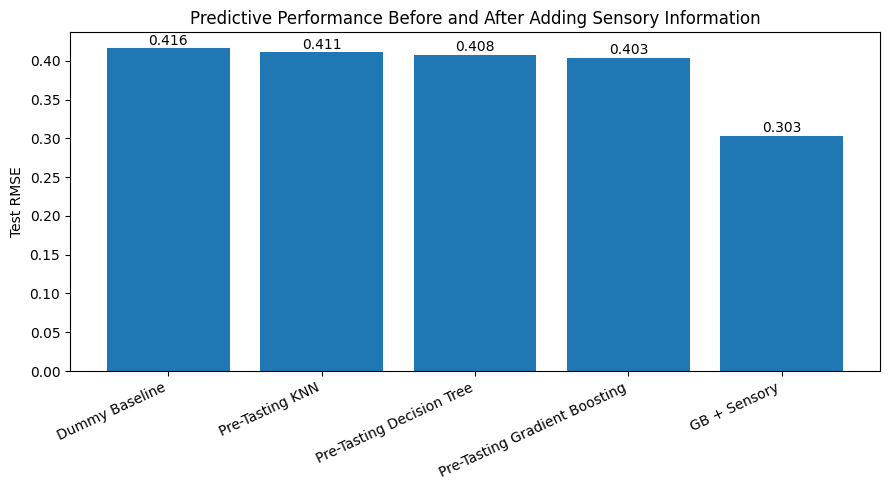

In [34]:
# Update and display comparison with Ridge and Lasso included
model_comparison_extended = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "KNN",
        "Decision Tree",
        "Gradient Boosting",
        "Random Forest",
        "Neural Network(MLP)",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "Train RMSE": [
        dummy_train_rmse,
        knn_train_rmse,
        dt_train_rmse,
        boost_train_rmse,
        rf_train_rmse,
        mlp_train_rmse,
        ridge_train_rmse,
        lasso_train_rmse
    ],
    "Test RMSE": [
        dummy_rmse,
        knn_rmse,
        dt_rmse,
        boost_rmse,
        rf_rmse,
        mlp_rmse,
        ridge_rmse,
        lasso_rmse
    ],
    "Test MAE": [
        dummy_mae,
        knn_mae,
        dt_mae,
        boost_mae,
        rf_mae,
        mlp_mae,
        ridge_mae,
        lasso_mae
    ]
})

model_comparison_extended = model_comparison_extended.sort_values("Test RMSE")
display(model_comparison_extended)

# Compare pre-tasting and sensory-enhanced model performance
model_names = ["Dummy Baseline", "Pre-Tasting KNN", "Pre-Tasting Decision Tree",
               "Pre-Tasting Gradient Boosting", "GB + Sensory"]
rmse_values = [dummy_rmse, knn_pre_rmse, dt_pre_rmse, gb_pre_rmse, boost_rmse]

plt.figure(figsize=(9, 5))
bars = plt.bar(model_names, rmse_values)
plt.ylabel("Test RMSE")
plt.title("Predictive Performance Before and After Adding Sensory Information")
plt.xticks(rotation=25, ha="right")
for bar, value in zip(bars, rmse_values):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005, f"{value:.3f}", ha="center")
plt.tight_layout()
plt.show()

In [35]:
import numpy as np
import pandas as pd

# Define the rounding exact match accuracy function
def exact_match_accuracy(pred, actual):
    rounded_pred = np.round(pred * 4) / 4
    return np.mean(rounded_pred == actual)

# Dictionary of predictions
predictions_dict = {
    "Dummy Baseline": y_test_pred_dummy,
    "KNN": y_test_pred_knn,
    "Decision Tree": y_test_pred_dt,
    "Gradient Boosting": y_test_pred_boost,
    "Random Forest": y_test_pred_rf,
    "Neural Network(MLP)": y_test_pred_mlp,
    "Ridge Regression": best_ridge.predict(X_test_scaled),
    "Lasso Regression": best_lasso.predict(X_test_scaled)
}

# Calculate exact match accuracy for each model
accuracy_results = []
for model_name, preds in predictions_dict.items():
    acc = exact_match_accuracy(preds, y_test)
    accuracy_results.append({"Model": model_name, "Exact Match Accuracy (within 0.25)": f"{acc * 100:.2f}%"})

# Display the results
accuracy_df = pd.DataFrame(accuracy_results).sort_values("Exact Match Accuracy (within 0.25)", ascending=False)
display(accuracy_df)

,Model,Exact Match Accuracy (within 0.25)
4,Random Forest,36.36%
7,Lasso Regression,35.70%
3,Gradient Boosting,35.05%
6,Ridge Regression,34.39%
2,Decision Tree,33.33%
5,Neural Network(MLP),27.27%
1,KNN,24.37%
0,Dummy Baseline,18.05%


--- Summary of Rating Differences (Actual - Predicted) ---


,Value
Mean Signed Error (Bias),-0.004703
Mean Absolute Error (MAE),0.236264
Median Absolute Error,0.180957
Max Over-estimation (Predicted > Actual),-1.297274
Max Under-estimation (Actual > Predicted),1.200295
Standard Deviation of Error,0.303303


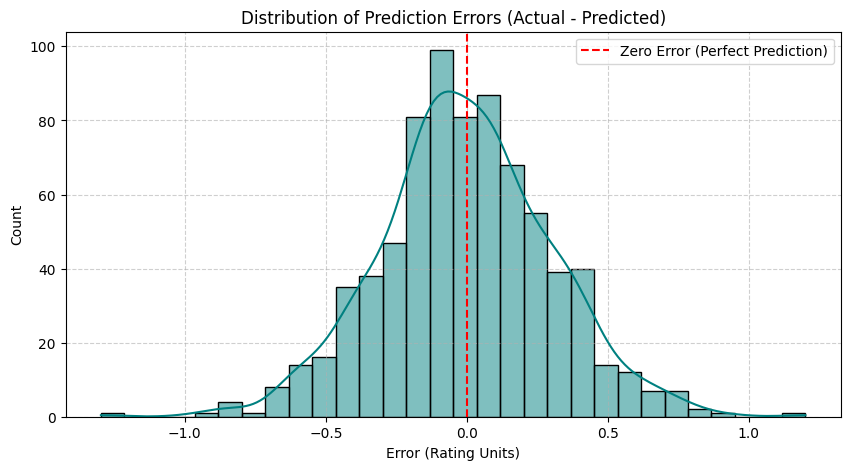

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate raw differences (Actual - Predicted) for the best model which is gradient boosting
raw_differences = y_test - y_test_pred_boost
abs_differences = np.abs(raw_differences)

# Compile summary statistics of the differences
diff_stats = pd.Series({
    'Mean Signed Error (Bias)': np.mean(raw_differences),
    'Mean Absolute Error (MAE)': np.mean(abs_differences),
    'Median Absolute Error': np.median(abs_differences),
    'Max Over-estimation (Predicted > Actual)': np.min(raw_differences),
    'Max Under-estimation (Actual > Predicted)': np.max(raw_differences),
    'Standard Deviation of Error': np.std(raw_differences)
})

print("--- Summary of Rating Differences (Actual - Predicted) ---")
display(diff_stats.to_frame(name="Value"))

# Plotting distribution of raw errors
plt.figure(figsize=(10, 5))
sns.histplot(raw_differences, kde=True, bins=30, color='teal')
plt.axvline(0, color='red', linestyle='--', label='Zero Error (Perfect Prediction)')
plt.title('Distribution of Prediction Errors (Actual - Predicted)')
plt.xlabel('Error (Rating Units)')
plt.ylabel('Count')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [37]:
# Create a DataFrame comparing individual actual ratings to predicted ratings
comparison_samples = pd.DataFrame({
    'Actual Rating': y_test,
    'Predicted Rating': np.round(y_test_pred_boost, 3),
    'Numeric Difference (Actual - Pred)': np.round(y_test - y_test_pred_boost, 3)
})

# Let's display the first 20 rows of this comparative view
print("--- Direct Comparison of Actual vs. Predicted Ratings (First 20 Test Samples) ---")
display(comparison_samples.head(20))

--- Direct Comparison of Actual vs. Predicted Ratings (First 20 Test Samples) ---


,Actual Rating,Predicted Rating,Numeric Difference (Actual - Pred)
0,2.75,2.959,-0.209
1,2.75,3.152,-0.402
2,2.75,2.761,-0.011
3,3.00,3.387,-0.387
4,3.25,3.414,-0.164
5,3.75,3.380,0.370
6,3.25,3.246,0.004
7,2.75,2.799,-0.049
8,3.00,2.629,0.371
9,3.75,3.734,0.016


What does this mean?  We can reasonably stay within the same integer rating if we round up our predictions
1. The typical miss is less than one rating step.  So half our predictions are off by less than a fifth of a point.
2. There’s no systematic bias. The mean signed error is −0.007, so the model has an equal chance to over- or under-predict.
3. A few big misses pull up the average. The worst cases are 1.33 too high and 0.94 too low. These are the very low and very high rated bars getting pulled toward the middle.

In [38]:
# Calculate the missing training RMSE for the Dummy Baseline
y_train_pred_dummy = dummy.predict(X_train)
dummy_train_rmse = np.sqrt(MSE(y_train, y_train_pred_dummy))

# Compile and display the model comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Baseline",
        "KNN",
        "Decision Tree",
        "Gradient Boosting",
        "Random Forest",
        "Neural Network(MLP)"
    ],
    "Train RMSE": [
        dummy_train_rmse,
        knn_train_rmse,
        dt_train_rmse,
        boost_train_rmse,
        rf_train_rmse,
        mlp_train_rmse
    ],
    "Test RMSE": [
        dummy_rmse,
        knn_rmse,
        dt_rmse,
        boost_rmse,
        rf_rmse,
        mlp_rmse
    ],
    "Test MAE": [
        dummy_mae,
        knn_mae,
        dt_mae,
        boost_mae,
        rf_mae,
        mlp_mae
    ]
})

model_comparison = model_comparison.sort_values(
    "Test RMSE"
)

display(model_comparison)

,Model,Train RMSE,Test RMSE,Test MAE
4,Random Forest,2.457569e-01,0.302833,0.237164
3,Gradient Boosting,2.674213e-01,0.303339,0.236264
2,Decision Tree,3.013790e-01,0.312581,0.247987
1,KNN,9.451463e-07,0.371588,0.299834
5,Neural Network(MLP),2.425485e-01,0.374551,0.291817
0,Dummy Baseline,4.571812e-01,0.416081,0.341947


In [39]:
boost_feature_importance = pd.Series(
    best_boost.feature_importances_,
    index=X_train.columns
).sort_values(
    ascending=False
)

display(
    boost_feature_importance.head(20)
)

,0
sentiment_total,0.873048
cocoa_numeric,0.042732
ingredients_Missing,0.011485
"ingredients_3- B,S,C",0.010193
ingredients_Other,0.009179
origin_Blend,0.007774
location_Belgium,0.005464
"ingredients_2- B,S",0.003790
location_U.K.,0.003628
location_Canada,0.003036


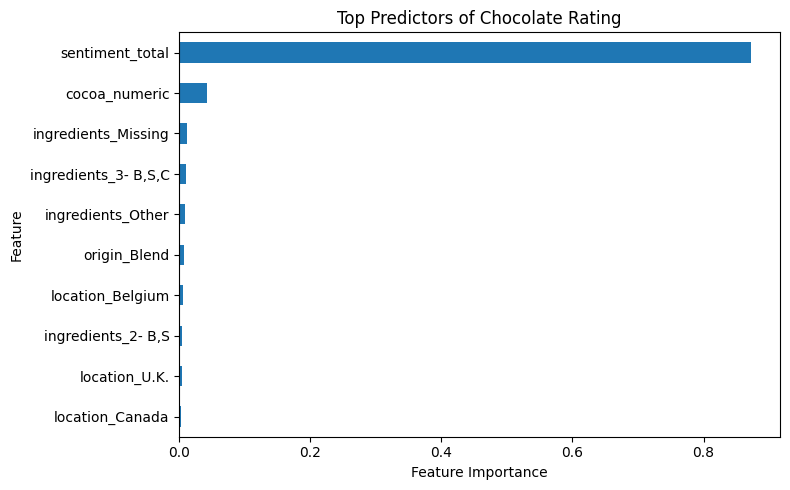

In [40]:
top_features = (
    boost_feature_importance
    .head(10)
    .sort_values()
)

plt.figure(figsize=(8, 5))

top_features.plot(
    kind="barh"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title(
    "Top Predictors of Chocolate Rating"
)

plt.tight_layout()
plt.show()

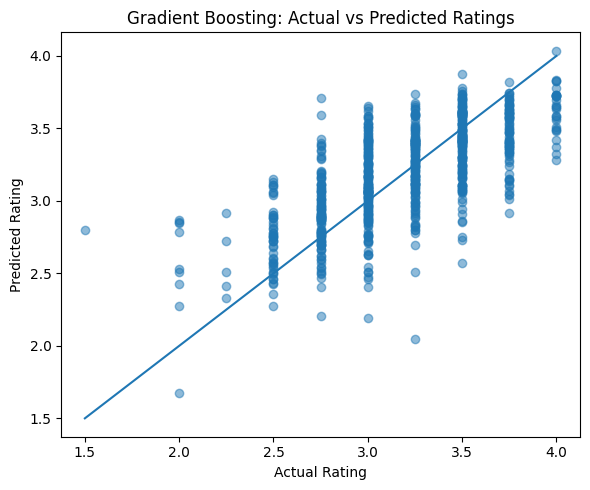

In [41]:
plt.figure(figsize=(6, 5))

plt.scatter(
    y_test,
    y_test_pred_boost,
    alpha=0.5
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")

plt.title(
    "Gradient Boosting: Actual vs Predicted Ratings"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

plt.tight_layout()
plt.show()

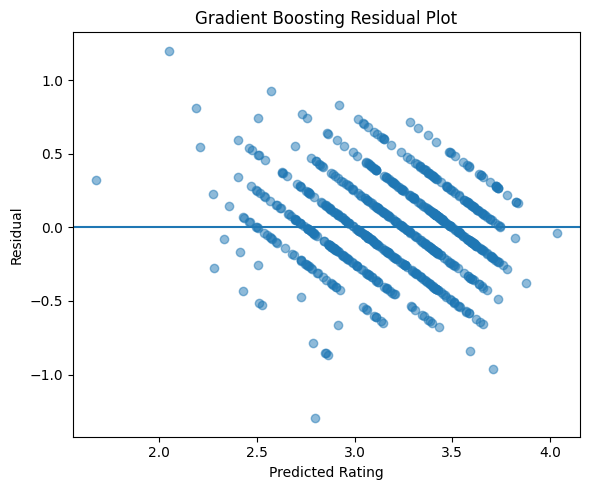

In [42]:
residuals = (
    y_test - y_test_pred_boost
)

plt.figure(figsize=(6, 5))

plt.scatter(
    y_test_pred_boost,
    residuals,
    alpha=0.5
)

plt.axhline(0)

plt.xlabel("Predicted Rating")
plt.ylabel("Residual")

plt.title(
    "Gradient Boosting Residual Plot"
)

plt.tight_layout()
plt.show()

In [43]:
error_details = choc_test[
    [
        "company_location",
        "country_of_bean_origin",
        "cocoa_percent",
        "ingredients",
        "most_memorable_characteristics",
        "rating"
    ]
].copy()

error_details["Predicted"] = (
    y_test_pred_boost
)

error_details["Absolute Error"] = abs(
    error_details["rating"]
    - error_details["Predicted"]
)

error_details = (
    error_details
    .sort_values(
        "Absolute Error",
        ascending=False
    )
)

display(
    error_details.head(20)
)

,company_location,country_of_bean_origin,cocoa_percent,ingredients,most_memorable_characteristics,rating,Predicted,Absolute Error
2118,U.S.A.,Ghana,67%,"3- B,S,C","perfume, strong chemical",1.50,2.797274,1.297274
2293,U.S.A.,Blend,99%,NaN,"spicy, ginger, bitter",3.25,2.049705,1.200295
1687,U.S.A.,Peru,75%,"3- B,S,C","spicy, red fruit, raisins",2.75,3.710906,0.960906
1427,Madagascar,Madagascar,75%,"5- B,S,C,V,L","sticky, bitter, nutty",3.50,2.572359,0.927641
1446,Italy,Ecuador,70%,"4- B,S,C,L","strong vanilla, some spice",2.00,2.865654,0.865654
883,Switzerland,Blend,62%,"5- B,S,C,V,L","malitol, cocoa",2.00,2.852183,0.852183
1165,Ecuador,Ecuador,80%,"4- B,S,C,L","perfume, burning",2.00,2.850119,0.850119
670,U.S.A.,Liberia,70%,"2- B,S","roasty, spicy, nutty",2.75,3.591669,0.841669
1428,Madagascar,Madagascar,70%,"5- B,S,C,V,L","sandy, woody, peanut butter",3.75,2.918169,0.831831
1772,U.S.A.,U.S.A.,60%,"5- B,S,C,V,L","muddy, pastey, sweet, vanilla",3.00,2.189258,0.810742


most important presensory (pre-tasting) characteristic is country of bean origin (followed closely by cocoa percentage).



In [44]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error

# 1. Define filters/masks for the different timeline blocks
mask_before_2020 = (choc_test["review_date"] < 2020).values
mask_2020_to_2023 = ((choc_test["review_date"] >= 2020) & (choc_test["review_date"] < 2024)).values

print(f"Total test samples: {len(y_test)}")
print(f"Older test samples (< 2020): {np.sum(mask_before_2020)}")
print(f"Recent test samples (2020 to 2023): {np.sum(mask_2020_to_2023)}\n")

# Exact match accuracy helper (predictions rounded to nearest 0.25)
def exact_match_accuracy(pred, actual):
    if len(actual) == 0:
        return np.nan
    rounded_pred = np.round(pred * 4) / 4
    return np.mean(rounded_pred == actual)

# 2. Compile full temporal exact match accuracy comparison table
temporal_accuracy = []
for model_name, preds in predictions_dict.items():
    acc_full = exact_match_accuracy(preds, y_test)
    acc_before_2020 = exact_match_accuracy(preds[mask_before_2020], y_test[mask_before_2020])
    acc_recent_pre_2024 = exact_match_accuracy(preds[mask_2020_to_2023], y_test[mask_2020_to_2023])

    temporal_accuracy.append({
        "Model": model_name,
        "Full-Time Accuracy": f"{acc_full * 100:.2f}%" if not np.isnan(acc_full) else "N/A",
        "Before 2020 Accuracy": f"{acc_before_2020 * 100:.2f}%" if not np.isnan(acc_before_2020) else "N/A",
        "Recent (2020-2023) Accuracy": f"{acc_recent_pre_2024 * 100:.2f}%" if not np.isnan(acc_recent_pre_2024) else "N/A"
    })

temporal_accuracy_df = pd.DataFrame(temporal_accuracy).sort_values("Recent (2020-2023) Accuracy", ascending=False)
print("--- Exact Match Accuracy (within 0.25 rating units) across timelines ---")
display(temporal_accuracy_df)

Total test samples: 759
Older test samples (< 2020): 665
Recent test samples (2020 to 2023): 94

--- Exact Match Accuracy (within 0.25 rating units) across timelines ---


,Model,Full-Time Accuracy,Before 2020 Accuracy,Recent (2020-2023) Accuracy
4,Random Forest,36.36%,35.94%,39.36%
3,Gradient Boosting,35.05%,34.59%,38.30%
6,Ridge Regression,34.39%,33.83%,38.30%
7,Lasso Regression,35.70%,35.49%,37.23%
2,Decision Tree,33.33%,32.93%,36.17%
5,Neural Network(MLP),27.27%,26.02%,36.17%
0,Dummy Baseline,18.05%,16.24%,30.85%
1,KNN,24.37%,23.46%,30.85%


In [45]:
feature_sets = {
    "All Predictors":
        list(X_train.columns),

    "Without Company Location":
        [
            col for col in X_train.columns
            if not col.startswith("location_")
        ],

    "Without Bean Origin":
        [
            col for col in X_train.columns
            if not col.startswith("origin_")
        ],

    "Without Sentiment":
        [
            col for col in X_train.columns
            if col != "sentiment_total"
        ],

    "Cocoa + Ingredients + Sentiment":
        [
            col for col in X_train.columns
            if (
                col == "cocoa_numeric"
                or col == "sentiment_total"
                or col.startswith("ingredients_")
            )
        ]
}

ablation_results = []

for name, features in feature_sets.items():

    model = GradientBoostingRegressor(
        random_state=0
    )

    model.fit(
        X_train[features],
        y_train
    )

    predictions = model.predict(
        X_test[features]
    )

    rmse = np.sqrt(
        MSE(y_test, predictions)
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    ablation_results.append([
        name,
        len(features),
        rmse,
        mae
    ])

ablation_results = pd.DataFrame(
    ablation_results,
    columns=[
        "Feature Set",
        "Number of Predictors",
        "Test RMSE",
        "Test MAE"
    ]
)

ablation_results = ablation_results.sort_values(
    "Test RMSE"
)

display(ablation_results)

,Feature Set,Number of Predictors,Test RMSE,Test MAE
2,Without Bean Origin,34,0.304010,0.238695
0,All Predictors,65,0.304291,0.236983
4,Cocoa + Ingredients + Sentiment,11,0.304766,0.238606
1,Without Company Location,42,0.307459,0.239637
3,Without Sentiment,64,0.403373,0.327264


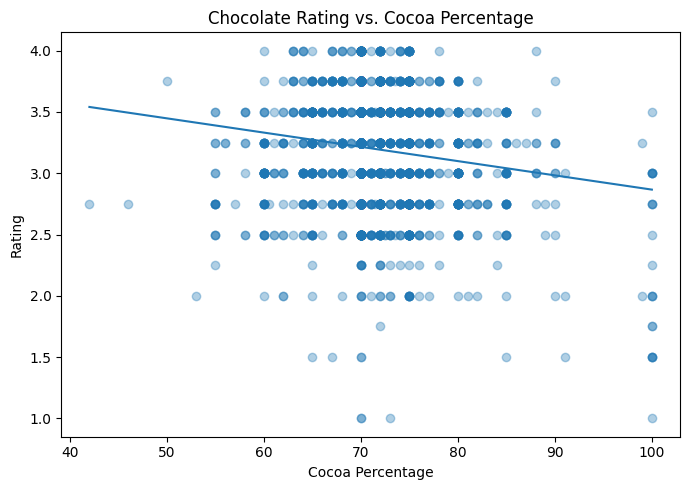

Correlation between cocoa percentage and rating: -0.147


In [46]:
plt.figure(figsize=(7, 5))

plt.scatter(
    choc["cocoa_numeric"],
    choc["rating"],
    alpha=0.35
)

z = np.polyfit(
    choc["cocoa_numeric"],
    choc["rating"],
    1
)

p = np.poly1d(z)

x_line = np.linspace(
    choc["cocoa_numeric"].min(),
    choc["cocoa_numeric"].max(),
    100
)

plt.plot(
    x_line,
    p(x_line),
)

plt.xlabel("Cocoa Percentage")
plt.ylabel("Rating")
plt.title("Chocolate Rating vs. Cocoa Percentage")

plt.tight_layout()
plt.show()

cocoa_rating_corr = choc[
    ["cocoa_numeric", "rating"]
].corr().iloc[0, 1]

print(
    "Correlation between cocoa percentage and rating:",
    round(cocoa_rating_corr, 3)
)

,count,mean,median,std
country_of_bean_origin,,,,
Madagascar,177,3.266949,3.25,0.387659
Nicaragua,100,3.255000,3.25,0.381021
Tanzania,79,3.234177,3.25,0.384686
Venezuela,253,3.231225,3.25,0.464934
Dominican Republic,226,3.215708,3.25,0.385410
Peru,244,3.197746,3.25,0.485473
Colombia,79,3.196203,3.25,0.423036
Bolivia,80,3.181250,3.25,0.435699
Ecuador,219,3.164384,3.25,0.512268


<Figure size 1000x600 with 0 Axes>

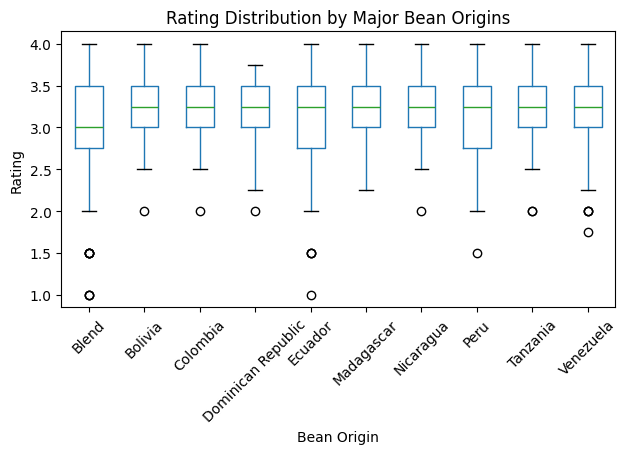

In [47]:
top_origins = (
    choc["country_of_bean_origin"]
    .value_counts()
    .head(10)
    .index
)

origin_data = choc[
    choc["country_of_bean_origin"].isin(top_origins)
].copy()

origin_summary = (
    origin_data
    .groupby("country_of_bean_origin")["rating"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("mean", ascending=False)
)

display(origin_summary)

plt.figure(figsize=(10, 6))

origin_data.boxplot(
    column="rating",
    by="country_of_bean_origin",
    grid=False,
    rot=45
)

plt.xlabel("Bean Origin")
plt.ylabel("Rating")
plt.title("Rating Distribution by Major Bean Origins")
plt.suptitle("")

plt.tight_layout()
plt.show()

In [48]:
sensory_dummies = (
    choc["most_memorable_characteristics"].fillna("").str.lower()
    .str.split(",")
    .apply(lambda items: "|".join(s.strip() for s in items if s.strip()))
    .str.get_dummies(sep="|")
)
print("Distinct descriptor phrases:", sensory_dummies.shape[1])

feature_counts = sensory_dummies.sum().sort_values(ascending=False)
q90 = feature_counts.quantile(0.90)
common_features = feature_counts[feature_counts >= q90].index
pca_features = sensory_dummies[common_features]

print("Number of sensory features used:", pca_features.shape[1])

Distinct descriptor phrases: 966
Number of sensory features used: 101


In [49]:
pca = PCA(
    n_components=2
)

pca_result = pca.fit_transform(
    pca_features
)

pca_df = pd.DataFrame(
    pca_result,
    columns=[
        "PC1",
        "PC2"
    ],
    index=choc.index
)

print(
    "PC1 explained variance:",
    round(
        pca.explained_variance_ratio_[0],
        4
    )
)

print(
    "PC2 explained variance:",
    round(
        pca.explained_variance_ratio_[1],
        4
    )
)

print(
    "Total explained variance:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

PC1 explained variance: 0.0551
PC2 explained variance: 0.0479
Total explained variance: 0.103


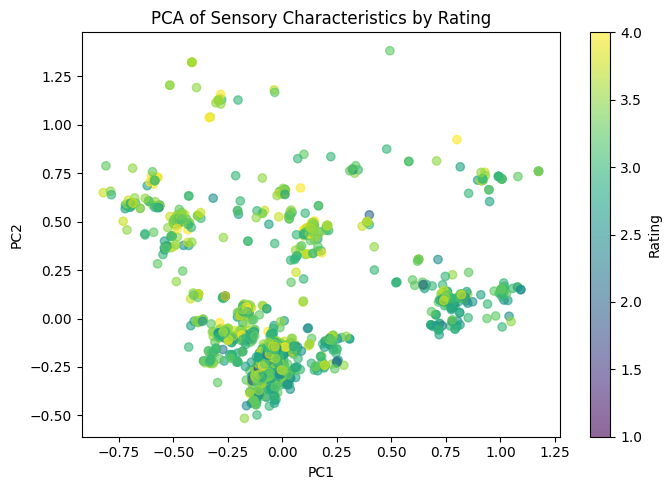

In [50]:
plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=choc["rating"],
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Rating"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA of Sensory Characteristics by Rating"
)

plt.tight_layout()
plt.show()

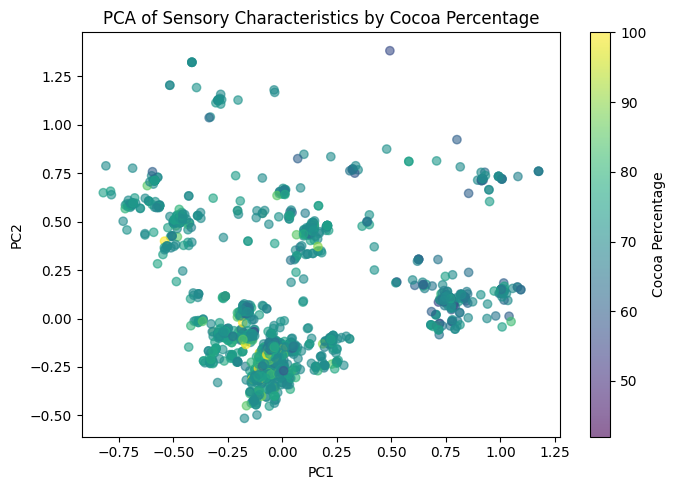

In [51]:
plt.figure(figsize=(7, 5))

scatter = plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=choc["cocoa_numeric"],
    alpha=0.6
)

plt.colorbar(
    scatter,
    label="Cocoa Percentage"
)

plt.xlabel("PC1")
plt.ylabel("PC2")

plt.title(
    "PCA of Sensory Characteristics by Cocoa Percentage"
)

plt.tight_layout()
plt.show()

### Finding the Best Flavor Profiles Based on Individual Characteristics
Let's analyze which tasting characteristics are associated with the highest average chocolate ratings using our vocabulary and word score mappings.

### Best and Worst Tasting Characteristics Based on Sentiment Impact Scores
Using the coefficients (`word_scores`) learned from our Ridge Regression model, we can directly see the positive and negative impact of each individual sensory descriptor on chocolate ratings.

In [52]:
# Convert word scores series to a DataFrame for visualization
word_impact_df = pd.DataFrame({
    'characteristic': word_scores.index,
    'impact_score': word_scores.values
}).sort_values(by='impact_score', ascending=False)

print("--- Top 15 Sensory Descriptors with the Most Positive Impact on Ratings ---")
display(word_impact_df.head(15))

print("\n--- Top 15 Sensory Descriptors with the Most Negative Impact on Ratings ---")
display(word_impact_df.tail(15))

--- Top 15 Sensory Descriptors with the Most Positive Impact on Ratings ---


,characteristic,impact_score
330,raspberry,0.232238
179,grape,0.228401
36,blackberry,0.221483
93,complex,0.219470
26,balanced,0.216853
156,fig,0.215646
123,distinct,0.212770
84,cinnamon,0.208634
109,dark,0.205689
393,strawberry,0.205329



--- Top 15 Sensory Descriptors with the Most Negative Impact on Ratings ---


,characteristic,impact_score
16,ashey,-0.260095
192,harsh,-0.264713
346,rubber,-0.266492
323,pungent,-0.291688
437,vanilla,-0.296570
171,fuel,-0.298534
271,musty,-0.300536
67,cardboard,-0.301891
121,dirt,-0.305401
431,unpleasant,-0.312696


In [53]:
profile = choc.copy()
profile["good"] = profile["rating"] >= 3.5
ingr = profile["ingredients"].fillna("Missing")

profile["cocoa band"] = pd.cut(profile["cocoa_numeric"], [0, 60, 65, 70, 75, 80, 100],
                               labels=["<=60%", "60-65%", "65-70%", "70-75%", "75-80%", ">80%"])
profile["has vanilla"] = ingr.str.contains(r"\bV\b")
profile["number of ingredients"] = ingr.str.extract(r"^(\d)")[0]
maker_counts = profile["company_manufacturer"].value_counts()
profile["established maker (10+ bars)"] = profile["company_manufacturer"].map(maker_counts) >= 10

def summarize(col):
    return (profile.groupby(col, observed=True)
            .agg(bars=("rating", "size"),
                 mean_rating=("rating", "mean"),
                 share_rated_3_5_plus=("good", "mean"))
            .round(2))

for col in ["cocoa band", "has vanilla", "number of ingredients", "established maker (10+ bars)"]:
    print(f"--- {col} ---")
    display(summarize(col))

# Origins with at least 30 bars: the best is only ~0.1 above average, while the spread inside each origin is 0.3-0.4
print("--- bean origins with at least 30 bars ---")
origin_summary = profile.groupby("country_of_bean_origin").agg(
    bars=("rating", "size"), mean_rating=("rating", "mean"), sd=("rating", "std"))
display(origin_summary[origin_summary["bars"] >= 30].sort_values("mean_rating", ascending=False).round(2).head(8))
print("Overall mean rating:", round(profile["rating"].mean(), 2))

--- cocoa band ---


,bars,mean_rating,share_rated_3_5_plus
cocoa band,,,
<=60%,77,2.98,0.14
60-65%,162,3.18,0.38
65-70%,1193,3.27,0.45
70-75%,789,3.18,0.36
75-80%,189,3.11,0.30
>80%,120,2.85,0.19


--- has vanilla ---


,bars,mean_rating,share_rated_3_5_plus
has vanilla,,,
False,2177,3.22,0.40
True,353,3.03,0.27


--- number of ingredients ---


,bars,mean_rating,share_rated_3_5_plus
number of ingredients,,,
1,6,2.96,0.17
2,750,3.22,0.39
3,1023,3.27,0.43
4,469,3.13,0.34
5,191,3.08,0.32
6,4,2.94,0.25


--- established maker (10+ bars) ---


,bars,mean_rating,share_rated_3_5_plus
established maker (10+ bars),,,
False,1640,3.12,0.31
True,890,3.33,0.52


--- bean origins with at least 30 bars ---


,bars,mean_rating,sd
country_of_bean_origin,,,
Vietnam,73,3.29,0.31
Papua New Guinea,50,3.28,0.38
Madagascar,177,3.27,0.39
Haiti,30,3.27,0.41
Brazil,78,3.26,0.42
Guatemala,62,3.26,0.36
Nicaragua,100,3.26,0.38
Trinidad,42,3.24,0.38


Overall mean rating: 3.2


In [54]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [55]:
# Part B: pre-tasting features --- Spelling clean-up
origin_map = {
    "Sao Tome": "Sao Tome & Principe", "Principe": "Sao Tome & Principe",
    "Trinidad": "Trinidad & Tobago", "Tobago": "Trinidad & Tobago",
    "Sumatra": "Indonesia", "Sulawesi": "Indonesia",   # islands of Indonesia
}
location_map = {
    "Amsterdam": "Netherlands", "Scotland": "U.K.", "Wales": "U.K.",
    "Sao Tome": "Sao Tome & Principe",
}

INGREDIENT_CODES = {"S": "sugar", "S*": "other_sweetener", "C": "cocoa_butter",
                    "V": "vanilla", "L": "lecithin", "Sa": "salt"}

def make_pre_tasting_features(df):
    """Columns that are known before a critic tastes the bar."""
    out = pd.DataFrame(index=df.index)
    out["origin"] = df["country_of_bean_origin"].replace(origin_map)
    out["location"] = df["company_location"].replace(location_map)
    out["maker"] = df["company_manufacturer"]
    out["cocoa"] = df["cocoa_numeric"]
    out["cocoa_dist70_sq"] = (df["cocoa_numeric"] - 70) ** 2

    codes = df["ingredients"].str.split("-").str[1].str.replace(" ", "").str.split(",")
    for code, name in INGREDIENT_CODES.items():
        out["has_" + name] = codes.apply(
            lambda lst: float(code in lst) if isinstance(lst, list) else np.nan)
    out["n_ingredients"] = df["ingredients"].str.split("-").str[0].astype(float)
    return out

Xp_train = make_pre_tasting_features(choc_train)
Xp_test = make_pre_tasting_features(choc_test)

cat_cols = ["origin", "location", "maker"]
num_cols = [c for c in Xp_train.columns if c not in cat_cols]

print("Pre-tasting inputs:", list(Xp_train.columns))
print("Training rows with missing ingredients:", Xp_train["n_ingredients"].isna().sum(),
      f"({Xp_train['n_ingredients'].isna().mean():.1%})")
display(Xp_train.head())


Pre-tasting inputs: ['origin', 'location', 'maker', 'cocoa', 'cocoa_dist70_sq', 'has_sugar', 'has_other_sweetener', 'has_cocoa_butter', 'has_vanilla', 'has_lecithin', 'has_salt', 'n_ingredients']
Training rows with missing ingredients: 68 (3.8%)


,origin,location,maker,cocoa,cocoa_dist70_sq,has_sugar,has_other_sweetener,has_cocoa_butter,has_vanilla,has_lecithin,has_salt,n_ingredients
87,Peru,Peru,Amazona,72.0,4.0,1.0,0.0,1.0,0.0,0.0,0.0,3.0
1423,Peru,Peru,Machu Picchu Trading Co.,70.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2529,Belize,Austria,Zotter,72.0,4.0,1.0,0.0,1.0,0.0,0.0,0.0,3.0
1776,Ecuador,Ecuador,Pacari,100.0,900.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
141,Costa Rica,U.S.A.,Arete,70.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0


In [56]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist"), cat_cols),
    ("num", Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), num_cols),
])

cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)

In [57]:
yc_train = (y_train >= 3.5).astype(int)
yc_test = (y_test >= 3.5).astype(int)
print(f"Share of bars rated >= 3.5: train {yc_train.mean():.1%}, test {yc_test.mean():.1%}")

cv_clf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

clf_searches = {
    "Logistic regression": GridSearchCV(
        Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=5000))]),
        {"model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10],
         "model__class_weight": [None, "balanced"]},
        cv=cv_clf, scoring="roc_auc"),
    "Decision tree": GridSearchCV(
        Pipeline([("prep", preprocess), ("model", DecisionTreeClassifier(class_weight="balanced", random_state=0))]),
        {"model__max_depth": [2, 3, 4, 5, 6, 8, 10, 12],
         "model__min_samples_leaf": [5, 10, 20, 40, 80, 120]},
        cv=cv_clf, scoring="roc_auc"),
    "kNN": GridSearchCV(
        Pipeline([("prep", preprocess), ("model", KNeighborsClassifier())]),
        {"model__n_neighbors": [5, 10, 20, 30, 50, 75, 100, 150, 200],
         "model__weights": ["uniform", "distance"]},
        cv=cv_clf, scoring="roc_auc"),
}

rows = []
dummy_clf = DummyClassifier(strategy="most_frequent").fit(Xp_train, yc_train)
rows.append(["Dummy (always 'not recommendable')", "-", 0.5, 0.5, 0.5])
for name, search in clf_searches.items():
    search.fit(Xp_train, yc_train)
    best = search.best_estimator_
    rows.append([name, search.best_params_, search.best_score_,
                 roc_auc_score(yc_train, best.predict_proba(Xp_train)[:, 1]),
                 roc_auc_score(yc_test, best.predict_proba(Xp_test)[:, 1])])

clf_table = pd.DataFrame(rows, columns=["Model", "Best settings", "CV AUC", "Train AUC", "Test AUC"])
display(clf_table.round(3))
print("AUC 0.5 = no better than random ordering; 1.0 = perfect ranking.")

Share of bars rated >= 3.5: train 39.5%, test 36.6%


,Model,Best settings,CV AUC,Train AUC,Test AUC
0,Dummy (always 'not recommendable'),-,0.500,0.500,0.500
1,Logistic regression,"{'model__C': 0.03, 'model__class_weight': 'bal...",0.644,0.683,0.636
2,Decision tree,"{'model__max_depth': 8, 'model__min_samples_le...",0.645,0.658,0.617
3,kNN,"{'model__n_neighbors': 50, 'model__weights': '...",0.640,0.668,0.609


AUC 0.5 = no better than random ordering; 1.0 = perfect ranking.


              Model  CV AUC
      Decision tree   0.645
Logistic regression   0.644
                kNN   0.640
Model used for the decision: Logistic regression


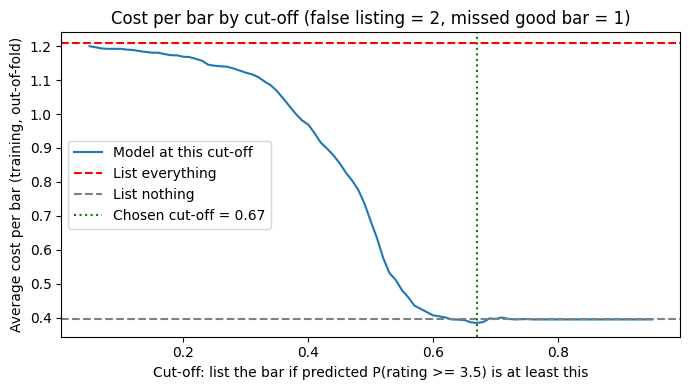

,Policy (test set),Bars listed,Cost per bar,Precision (listed that were good),Recall (good bars caught)
0,"Model, cost-based cut-off (0.67)",65,0.368,0.662,0.155
1,"Model, default cut-off (0.5)",400,0.705,0.452,0.651
2,List everything (no model),759,1.267,0.366,1.000
3,List nothing (no model),0,0.366,0.000,0.000


In [58]:
COST_FALSE_LISTING = 2
COST_MISSED_GOOD = 1

def listing_cost(y_true, listed, c_fp=COST_FALSE_LISTING, c_fn=COST_MISSED_GOOD):
    """Average cost per bar of a listing decision (lower is better)."""
    listed = np.asarray(listed).astype(bool)
    false_listing = np.sum(listed & (y_true == 0))
    missed_good = np.sum(~listed & (y_true == 1))
    return (c_fp * false_listing + c_fn * missed_good) / len(y_true)

ranked = clf_table.iloc[1:].sort_values("CV AUC", ascending=False)
top_auc = ranked["CV AUC"].iloc[0]
logit_auc = ranked.loc[ranked["Model"] == "Logistic regression", "CV AUC"].iloc[0]
best_clf_name = "Logistic regression" if top_auc - logit_auc <= 0.01 else ranked["Model"].iloc[0]
best_clf = clf_searches[best_clf_name].best_estimator_
print(ranked[["Model", "CV AUC"]].round(3).to_string(index=False))
print("Model used for the decision:", best_clf_name)

oof_prob = cross_val_predict(best_clf, Xp_train, yc_train, cv=cv_clf, method="predict_proba")[:, 1]

thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)
train_costs = [listing_cost(yc_train, oof_prob >= t) for t in thresholds]
best_t = thresholds[int(np.argmin(train_costs))]

plt.figure(figsize=(7, 4))
plt.plot(thresholds, train_costs, label="Model at this cut-off")
plt.axhline(listing_cost(yc_train, np.ones_like(yc_train)), color="red", linestyle="--", label="List everything")
plt.axhline(listing_cost(yc_train, np.zeros_like(yc_train)), color="gray", linestyle="--", label="List nothing")
plt.axvline(best_t, color="green", linestyle=":", label=f"Chosen cut-off = {best_t}")
plt.xlabel("Cut-off: list the bar if predicted P(rating >= 3.5) is at least this")
plt.ylabel("Average cost per bar (training, out-of-fold)")
plt.title(f"Cost per bar by cut-off (false listing = {COST_FALSE_LISTING}, missed good bar = {COST_MISSED_GOOD})")
plt.legend()
plt.tight_layout()
plt.show()

test_prob = best_clf.predict_proba(Xp_test)[:, 1]
policies = {
    f"Model, cost-based cut-off ({best_t})": test_prob >= best_t,
    "Model, default cut-off (0.5)": test_prob >= 0.5,
    "List everything (no model)": np.ones_like(yc_test, dtype=bool),
    "List nothing (no model)": np.zeros_like(yc_test, dtype=bool),
}
rows = []
for name, listed in policies.items():
    rows.append([name, listed.sum(), listing_cost(yc_test, listed),
                 precision_score(yc_test, listed, zero_division=0), recall_score(yc_test, listed)])
policy_table = pd.DataFrame(rows, columns=["Policy (test set)", "Bars listed", "Cost per bar",
                                           "Precision (listed that were good)", "Recall (good bars caught)"])
display(policy_table.round(3))

In [59]:
rows = []
for c_fp, c_fn in [(1, 3), (1, 2), (1, 1), (2, 1), (3, 1)]:
    costs = [listing_cost(yc_train, oof_prob >= t, c_fp, c_fn) for t in thresholds]
    t = thresholds[int(np.argmin(costs))]
    model_cost = listing_cost(yc_test, test_prob >= t, c_fp, c_fn)
    all_cost = listing_cost(yc_test, np.ones_like(yc_test), c_fp, c_fn)
    none_cost = listing_cost(yc_test, np.zeros_like(yc_test), c_fp, c_fn)
    best_simple = min(all_cost, none_cost)
    rows.append([f"{c_fp} : {c_fn}", t, model_cost, all_cost, none_cost,
                 f"{1 - model_cost / best_simple:.0%}"])
display(pd.DataFrame(rows, columns=["False listing : missed good", "Chosen cut-off", "Model cost",
                                    "List-all cost", "List-none cost",
                                    "Saving vs best simple policy"]).round(3))

,False listing : missed good,Chosen cut-off,Model cost,List-all cost,List-none cost,Saving vs best simple policy
0,1 : 3,0.36,0.588,0.634,1.099,7%
1,1 : 2,0.46,0.545,0.634,0.733,14%
2,1 : 1,0.60,0.356,0.634,0.366,3%
3,2 : 1,0.67,0.368,1.267,0.366,-0%
4,3 : 1,0.76,0.366,1.901,0.366,0%


In [60]:
diag = choc_test[["company_manufacturer", "company_location", "country_of_bean_origin",
                  "cocoa_percent", "ingredients", "review_date", "rating"]].copy()
diag["P(rating >= 3.5)"] = test_prob
diag["listed"] = test_prob >= best_t
diag["actually good"] = yc_test.astype(bool)
diag["error"] = diag["listed"] != diag["actually good"]

print("Most confident 'good' predictions:")
display(diag.sort_values("P(rating >= 3.5)", ascending=False).head(5).round(2))
print("Most confident 'not good' predictions:")
display(diag.sort_values("P(rating >= 3.5)").head(5).round(2))

Most confident 'good' predictions:


,company_manufacturer,company_location,country_of_bean_origin,cocoa_percent,ingredients,review_date,rating,P(rating >= 3.5),listed,actually good,error
2190,Soma,Canada,Madagascar,70%,"3- B,S,C",2021,3.50,0.75,True,True,False
2188,Soma,Canada,Venezuela,70%,"3- B,S,C",2018,4.00,0.73,True,True,False
2166,Soma,Canada,Venezuela,70%,"3- B,S,C",2013,4.00,0.73,True,True,False
2142,Soma,Canada,Venezuela,70%,"3- B,S,C",2009,3.75,0.73,True,True,False
2161,Soma,Canada,Venezuela,70%,"3- B,S,C",2013,3.25,0.73,True,False,True


Most confident 'not good' predictions:


,company_manufacturer,company_location,country_of_bean_origin,cocoa_percent,ingredients,review_date,rating,P(rating >= 3.5),listed,actually good,error
1106,Habitual,Canada,Blend,100%,NaN,2014,2.00,0.03,False,False,False
2293,TCHO,U.S.A.,Blend,99%,NaN,2012,3.25,0.03,False,False,False
2424,Vintage Plantations (Tulicorp),U.S.A.,Ecuador,100%,NaN,2007,2.00,0.03,False,False,False
1199,Hotel Chocolat (Coppeneur),U.K.,Dominican Republic,100%,NaN,2013,2.75,0.04,False,False,False
2087,Sirene,Canada,Ecuador,100%,1- B,2015,3.00,0.05,False,False,False


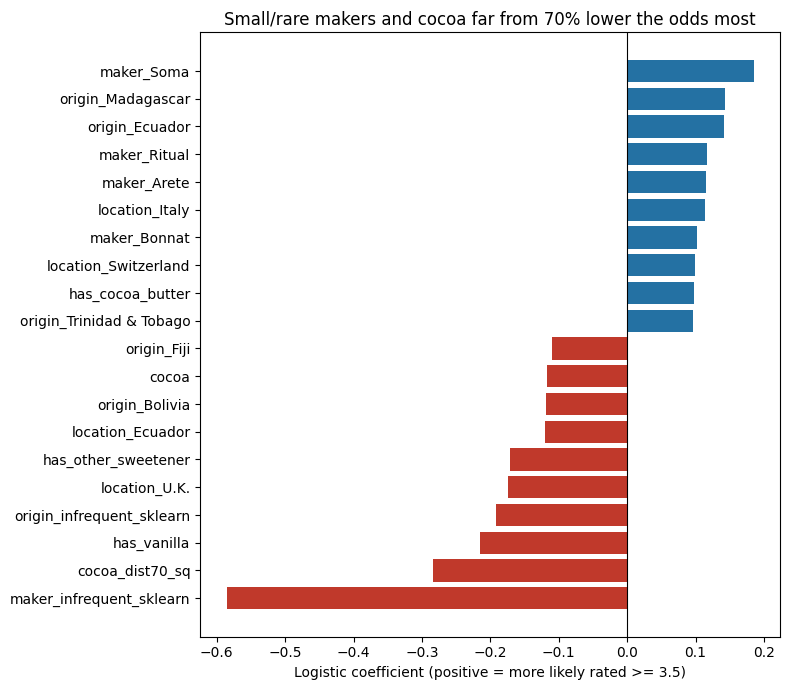

Decision tree: top 10 feature importances


,0
maker_infrequent_sklearn,0.413
cocoa_dist70_sq,0.318
has_vanilla,0.085
n_ingredients,0.079
has_cocoa_butter,0.038
location_U.S.A.,0.034
cocoa,0.033
origin_Ecuador,0.000
origin_Fiji,0.000
origin_Ghana,0.000


In [61]:
logit_best = clf_searches["Logistic regression"].best_estimator_
names = logit_best.named_steps["prep"].get_feature_names_out()
names = [n.replace("cat__", "").replace("num__", "").replace("missingindicator_", "missing_") for n in names]
coefs = pd.Series(logit_best.named_steps["model"].coef_[0], index=names).sort_values()

top = pd.concat([coefs.head(10), coefs.tail(10)])
plt.figure(figsize=(8, 7))
colors = ["#c0392b" if v < 0 else "#2471a3" for v in top]
plt.barh(top.index, top.values, color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Logistic coefficient (positive = more likely rated >= 3.5)")
plt.title("Small/rare makers and cocoa far from 70% lower the odds most")
plt.tight_layout()
plt.show()

tree_best = clf_searches["Decision tree"].best_estimator_
tnames = [n.replace("cat__", "").replace("num__", "") for n in tree_best.named_steps["prep"].get_feature_names_out()]
imp = pd.Series(tree_best.named_steps["model"].feature_importances_, index=tnames).sort_values(ascending=False)
print("Decision tree: top 10 feature importances")
display(imp.head(10).round(3))

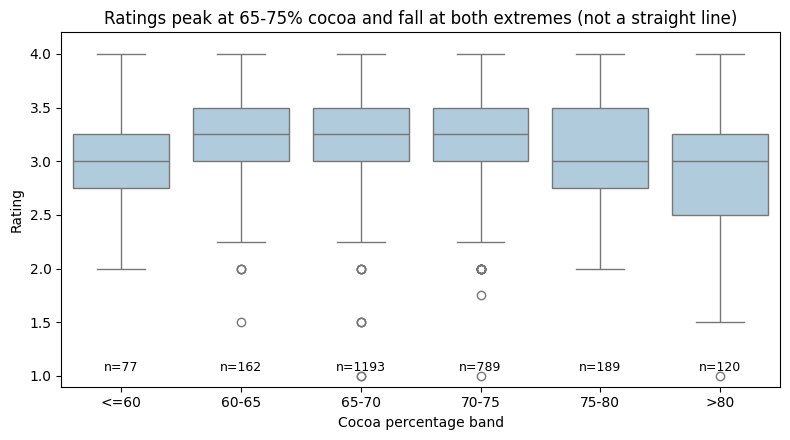

,count,mean,median,std
cocoa_numeric,,,,
<=60,77,2.98,3.00,0.38
60-65,162,3.18,3.25,0.45
65-70,1193,3.27,3.25,0.42
70-75,789,3.18,3.25,0.44
75-80,189,3.11,3.00,0.40
>80,120,2.85,3.00,0.58


In [62]:
#Part C1: rating by cocoa
bands = pd.cut(choc["cocoa_numeric"], [0, 60, 65, 70, 75, 80, 100],
               labels=["<=60", "60-65", "65-70", "70-75", "75-80", ">80"])
plt.figure(figsize=(8, 4.5))
ax = sns.boxplot(x=bands, y=choc["rating"], color="#a9cce3")
for i, (label, n) in enumerate(bands.value_counts(sort=False).items()):
    ax.text(i, 1.05, f"n={n}", ha="center", fontsize=9)
plt.xlabel("Cocoa percentage band")
plt.ylabel("Rating")
plt.ylim(0.9, 4.2)
plt.title("Ratings peak at 65-75% cocoa and fall at both extremes (not a straight line)")
plt.tight_layout()
plt.show()

display(choc.groupby(bands, observed=True)["rating"].agg(["count", "mean", "median", "std"]).round(2))

Bars with 65-75% cocoa: 2072 of 2530


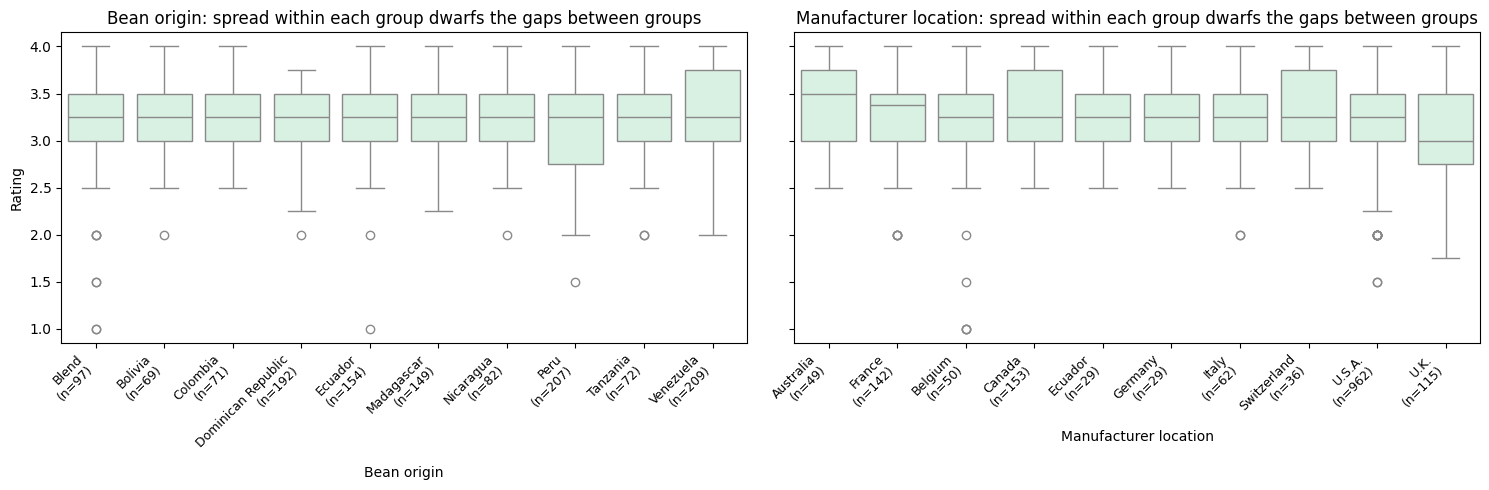

Bean origin (65-75% cocoa): range of group means = 0.12, typical spread inside a group (median IQR) = 0.50


,count,median,mean,std,IQR
origin,,,,,
Nicaragua,82,3.25,3.29,0.37,0.50
Madagascar,149,3.25,3.29,0.38,0.50
Venezuela,209,3.25,3.29,0.45,0.75
Ecuador,154,3.25,3.27,0.45,0.50
Tanzania,72,3.25,3.25,0.40,0.50
Dominican Republic,192,3.25,3.23,0.38,0.50
Bolivia,69,3.25,3.21,0.45,0.50
Colombia,71,3.25,3.20,0.41,0.50
Peru,207,3.25,3.20,0.48,0.75


Manufacturer location (65-75% cocoa): range of group means = 0.27, typical spread inside a group (median IQR) = 0.50


,count,median,mean,std,IQR
location,,,,,
Switzerland,36,3.25,3.38,0.42,0.75
Australia,49,3.50,3.37,0.41,0.75
Canada,153,3.25,3.33,0.39,0.75
Germany,29,3.25,3.29,0.37,0.50
France,142,3.38,3.29,0.45,0.50
Italy,62,3.25,3.29,0.44,0.50
Ecuador,29,3.25,3.28,0.41,0.50
U.S.A.,962,3.25,3.22,0.42,0.50
U.K.,115,3.00,3.13,0.45,0.75


In [63]:
# Hold the third variable fixed: only bars with 65-75% cocoa
mid = choc[(choc["cocoa_numeric"] >= 65) & (choc["cocoa_numeric"] <= 75)].copy()
mid["origin"] = mid["country_of_bean_origin"].replace(origin_map)
mid["location"] = mid["company_location"].replace(location_map)
print(f"Bars with 65-75% cocoa: {len(mid)} of {len(choc)}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
summaries = {}
for ax, col, title in [(axes[0], "origin", "Bean origin"), (axes[1], "location", "Manufacturer location")]:
    top10 = mid[col].value_counts().head(10).index
    sub = mid[mid[col].isin(top10)]
    order = sub.groupby(col)["rating"].median().sort_values(ascending=False).index
    sns.boxplot(data=sub, x=col, y="rating", order=order, color="#d5f5e3", ax=ax)
    counts = sub[col].value_counts()
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"{o}\n(n={counts[o]})" for o in order], rotation=45, ha="right", fontsize=9)
    ax.set_xlabel(title)
    ax.set_ylabel("Rating")
    ax.set_title(f"{title}: spread within each group dwarfs the gaps between groups")
    s = sub.groupby(col)["rating"].agg(["count", "median", "mean", "std"])
    s["IQR"] = sub.groupby(col)["rating"].quantile(0.75) - sub.groupby(col)["rating"].quantile(0.25)
    summaries[title] = s.sort_values("mean", ascending=False)
plt.tight_layout()
plt.show()

for title, s in summaries.items():
    print(f"{title} (65-75% cocoa): range of group means = {s['mean'].max() - s['mean'].min():.2f}, "
          f"typical spread inside a group (median IQR) = {s['IQR'].median():.2f}")
    display(s.round(2))

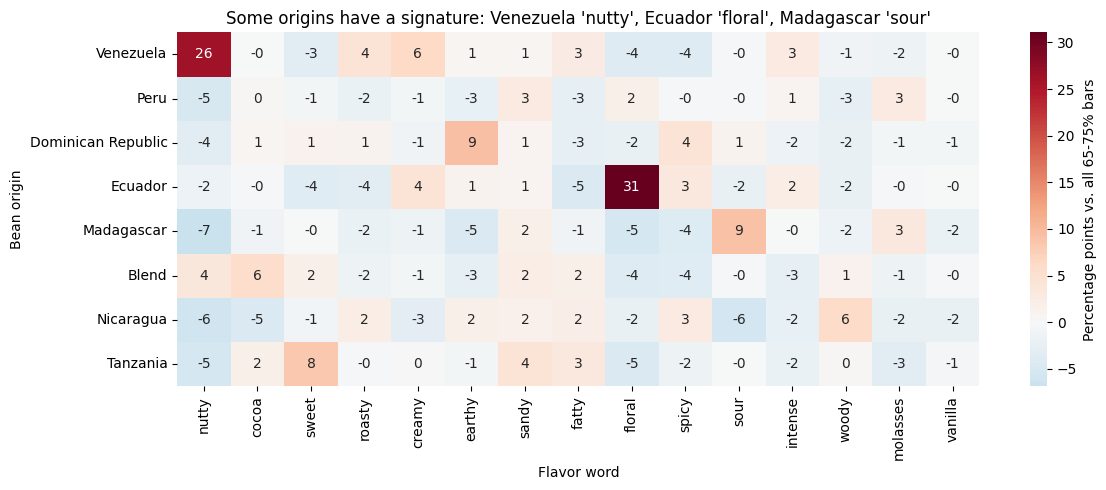

In [64]:
# Share of bars mentioning each common flavor word, by origin, compared with all 65-75% bars
mid_words = sensory_dummies.loc[mid.index]
top_words = mid_words.sum().sort_values(ascending=False).head(15).index
top_origins = mid["origin"].value_counts().head(8).index

overall_share = mid_words[top_words].mean()
profile = mid_words[top_words].groupby(mid["origin"]).mean().loc[top_origins]
lift = profile - overall_share          # + means this origin mentions the word more often than average

plt.figure(figsize=(12, 5))
sns.heatmap(lift * 100, cmap="RdBu_r", center=0, annot=True, fmt=".0f",
            cbar_kws={"label": "Percentage points vs. all 65-75% bars"})
plt.xlabel("Flavor word")
plt.ylabel("Bean origin")
plt.title("Some origins have a signature: Venezuela 'nutty', Ecuador 'floral', Madagascar 'sour'")
plt.tight_layout()
plt.show()

Unscaled: components needed for 50% of variance = 17 of 101
Scaled: components needed for 50% of variance = 42 of 101


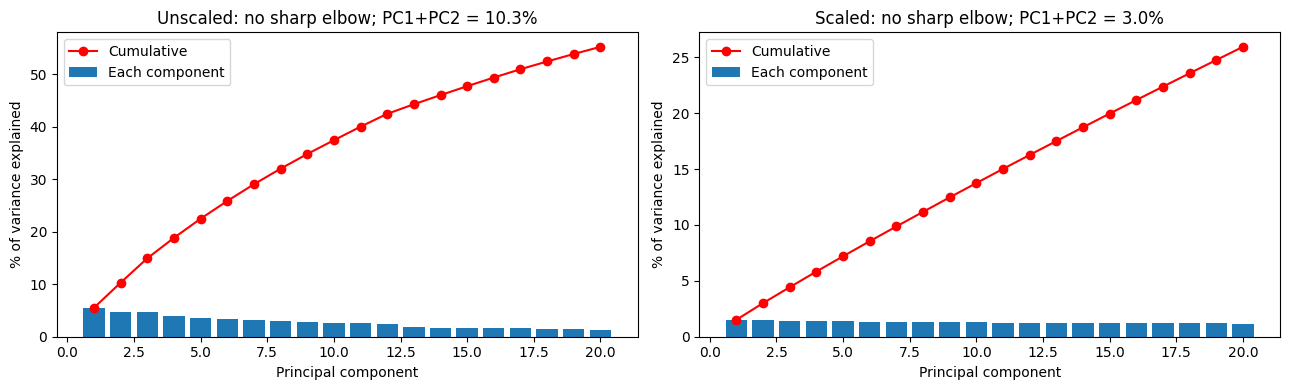

In [65]:
# Scree plot comparing scaled vs unscaled PCA to decide how many components to keep
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for scaled, ax in [(False, axes[0]), (True, axes[1])]:
    data = StandardScaler().fit_transform(pca_features) if scaled else pca_features
    p = PCA().fit(data)
    k = 20
    ax.bar(range(1, k + 1), p.explained_variance_ratio_[:k] * 100, label="Each component")
    ax.plot(range(1, k + 1), np.cumsum(p.explained_variance_ratio_[:k]) * 100, "ro-", label="Cumulative")
    ax.set_xlabel("Principal component")
    ax.set_ylabel("% of variance explained")
    ax.set_title(f"{'Scaled' if scaled else 'Unscaled'}: no sharp elbow; PC1+PC2 = "
                 f"{p.explained_variance_ratio_[:2].sum():.1%}")
    ax.legend()
    print(f"{'Scaled' if scaled else 'Unscaled'}: components needed for 50% of variance =",
          int(np.argmax(np.cumsum(p.explained_variance_ratio_) >= 0.5)) + 1, "of", pca_features.shape[1])
plt.tight_layout()
plt.show()